# Brain Tumor MRI Classification — Fresh Training (No Previous Project Models)

**Purpose:** train new models using the local `Tumour` dataset. This notebook does **not** load `cnn_model.h5`, `resnet_model.h5`, `best_model.h5`, or any previous project checkpoint.

## Project objective
Classify MRI images into the four dataset categories (expected folder names: `glioma`, `meningioma`, `notumor`, `pituitary`) and compare:
1. A custom CNN initialized randomly and trained from scratch.
2. ResNet50 with generic ImageNet weights, then a new task-specific classification head and optional fine-tuning. This is transfer learning, as requested by the project guide; it does not reuse any previous project model.

## Important truth about the 80% requirement
The notebook uses a **strict acceptance threshold of confidence > 0.80**. It cannot guarantee that every image will receive >80% confidence or that an >80% score is correct. The model must earn good validation/test performance. Predictions at or below 80% are marked `REVIEW REQUIRED`; scores are never artificially increased.

## Local dataset
`C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour`

Expected layout: `train/<class>`, `valid/<class>`, `test/<class>`. Run sections in order. Each code section has a purpose note and explanation.

## 0. Environment and reproducibility

**Purpose:** import required libraries, set random seeds and print software/hardware versions.

**What happens:** TensorFlow/Keras builds and trains the networks. Scikit-learn computes evaluation metrics. Matplotlib plots learning curves and confusion matrices.

**What this block does:** This block imports the libraries used throughout the notebook and fixes random seeds for repeatable experiments.

**Why it matters:** It also prints the TensorFlow, Keras and available device information so you can confirm the training environment.

In [ ]:
from pathlib import Path
import os, random, json, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python environment ready")
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Devices:", tf.config.list_physical_devices())

Python environment ready
TensorFlow: 2.21.0
Keras: 3.12.4
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Project paths and configuration

**Purpose:** connect to your real dataset folder and create a separate destination for newly trained models.

**What happens:** validates `train`, `valid`, and `test` before training. All newly trained models and reports go into `fresh_training_outputs`; old `.h5` files are not read or overwritten.

**Your confirmed dataset path:** `C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour`.

**What this block does:** This block defines the dataset folders, image size, batch size, training limits and output locations.

**Why it matters:** It checks that the train, validation and test folders exist before any images are loaded.

In [ ]:
DATASET_DIR = Path(r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour")
TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"
TEST_DIR  = DATASET_DIR / "test"

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "fresh_training_outputs"
MODEL_DIR = OUTPUT_DIR / "models"
REPORT_DIR = OUTPUT_DIR / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16  # conservative for 16 GB RAM / CPU; increase only if stable
EPOCHS_CNN = 30
EPOCHS_HEAD = 12
EPOCHS_FINE = 10
CONFIDENCE_THRESHOLD = 0.80  # strict: accepted only when probability > 80%

for folder in (TRAIN_DIR, VALID_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f"Dataset folder not found: {folder}")

print("Dataset path validated:", DATASET_DIR)
print("New outputs will be saved to:", OUTPUT_DIR)
print("No previous project model path is used.")

Dataset path validated: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour
New outputs will be saved to: c:\Users\Gokul\Downloads\Brain_Tumor_Project_\fresh_training_outputs
No previous project model path is used.


## 2. Dataset audit and class consistency

**Purpose:** verify class folders, count images, and catch missing/mismatched categories before training.

**What happens:** Keras reads class folders alphabetically. The same class order must exist in train, validation and test. We stop if it differs, because wrong label ordering invalidates training/evaluation.

**What this block does:** This block counts supported image files in each class folder and checks that all three dataset splits contain the same classes.

**Why it matters:** It stops early if a class is missing or empty, helping prevent incorrect labels during training.

In [ ]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def class_image_counts(split_dir):
    result = {}
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        result[class_dir.name] = sum(
            1 for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in VALID_EXTS
        )
    return result

counts = {
    "train": class_image_counts(TRAIN_DIR),
    "valid": class_image_counts(VALID_DIR),
    "test": class_image_counts(TEST_DIR),
}
display(pd.DataFrame(counts).fillna(0).astype(int))

class_names = sorted(counts["train"])
if len(class_names) < 2:
    raise ValueError("Expected at least two class folders.")
for split, split_counts in counts.items():
    if sorted(split_counts) != class_names:
        raise ValueError(f"Class folder mismatch in {split}: {sorted(split_counts)}")
    if any(n == 0 for n in split_counts.values()):
        raise ValueError(f"At least one class has no images in {split}: {split_counts}")

print("Class order:", class_names)
print("Class count:", len(class_names))

,train,valid,test
glioma,564,161,80
meningioma,358,124,63
no_tumor,335,99,49
pituitary,438,118,54


Class order: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Class count: 4


## 3. Inspect sample MRI images

**Purpose:** visually inspect a few files and confirm that folders contain readable MRI images rather than unrelated files.

**What happens:** displays one sample from each training class. Visual inspection does not diagnose an image; it is a data-quality check.

**What this block does:** This block displays one example MRI image from each training class.

**Why it matters:** Use it to check that the files look like MRI images and that the class folders appear to contain the expected image types.

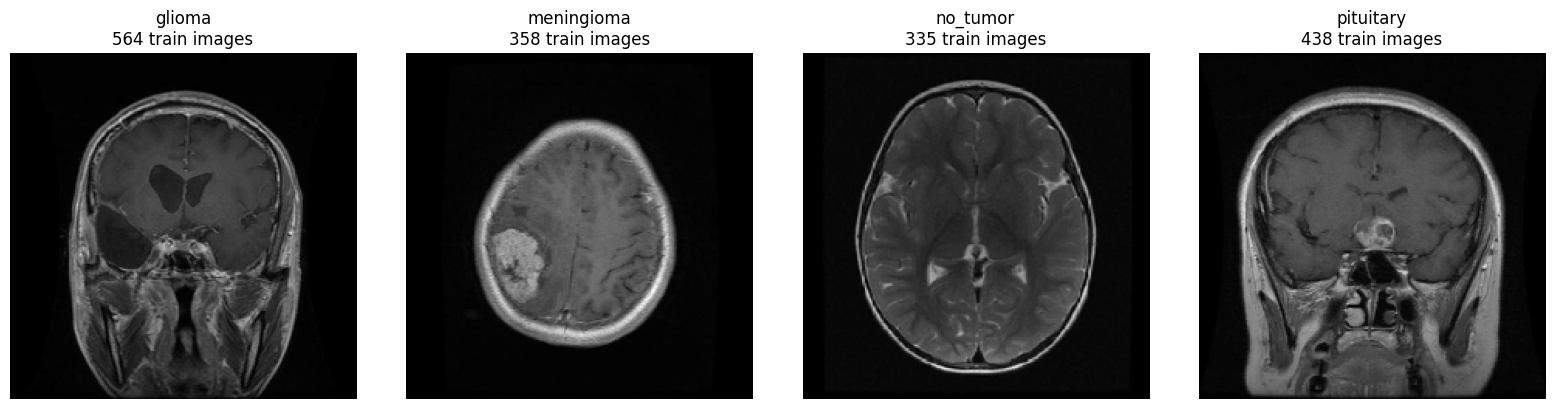

In [ ]:
fig, axes = plt.subplots(1, len(class_names), figsize=(4 * len(class_names), 4))
if len(class_names) == 1:
    axes = [axes]
for ax, name in zip(axes, class_names):
    files = [p for p in (TRAIN_DIR / name).rglob("*")
             if p.is_file() and p.suffix.lower() in VALID_EXTS]
    img = keras.utils.load_img(files[0], target_size=IMAGE_SIZE, color_mode="rgb")
    ax.imshow(img)
    ax.set_title(f"{name}\n{len(files)} train images")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Build deterministic generators

**Purpose:** create separate input pipelines for the custom CNN and ResNet50.

**What happens:** the custom CNN follows the project guide's 0–1 normalization. ResNet50 with ImageNet initialization uses the official ResNet50 preprocessing function. Training augmentation is applied only to training images; validation and test data are not augmented. Test order is fixed (`shuffle=False`).

**Important:** augmentation changes only training samples; it does not create new independent patient cases. If patient identifiers exist, split by patient before training to prevent leakage.

**What this block does:** This block creates separate image generators for the Custom CNN and ResNet50.

**Why it matters:** The CNN receives pixel values scaled to 0–1, while ResNet50 receives its required preprocessing; validation and test generators do not shuffle images.

In [ ]:
# Custom CNN: pixel values scaled to 0..1
cnn_train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True
).flow_from_directory(
    TRAIN_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True, seed=SEED
)
cnn_valid_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    VALID_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)
cnn_test_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    TEST_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)

# ResNet50: official preprocessing for ImageNet-pretrained feature extractor
resnet_preprocess = keras.applications.resnet50.preprocess_input
resnet_train_gen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=False  
).flow_from_directory(
    TRAIN_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True, seed=SEED
)
resnet_valid_gen = ImageDataGenerator(preprocessing_function=resnet_preprocess).flow_from_directory(
    VALID_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)
resnet_test_gen = ImageDataGenerator(preprocessing_function=resnet_preprocess).flow_from_directory(
    TEST_DIR, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)

class_indices = cnn_train_gen.class_indices
assert class_indices == cnn_valid_gen.class_indices == cnn_test_gen.class_indices
assert class_indices == resnet_train_gen.class_indices == resnet_valid_gen.class_indices == resnet_test_gen.class_indices
print("Verified class mapping:", class_indices)

with open(OUTPUT_DIR / "class_indices.json", "w", encoding="utf-8") as f:
    json.dump(class_indices, f, indent=2)

Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.
Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.
Verified class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


## 5. Handle class imbalance

**Purpose:** calculate class weights so that rare classes can contribute meaningfully to the loss.

**What happens:** weights are calculated from training labels only. This does not duplicate images and does not alter validation/test labels.

**What this block does:** This block calculates class weights from the training labels to reduce the effect of class imbalance.

**Why it matters:** The weights influence training loss without copying images or changing validation and test data.

In [ ]:
classes = np.unique(cnn_train_gen.classes)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=cnn_train_gen.classes
)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {0: 0.7513297872340425, 1: 1.183659217877095, 2: 1.2649253731343284, 3: 0.9674657534246576}


## 6. Create a custom CNN from random initialization

**Purpose:** satisfy the project requirement to design a custom CNN from scratch.

**What happens:** convolution layers learn image patterns; batch normalization stabilizes training; max pooling reduces spatial size; dropout helps reduce overfitting; softmax produces one score per class. No previous project model or pretrained weights are loaded.

**What this block does:** This block builds the Custom CNN from randomly initialized convolution layers, normalization, pooling and dropout.

**Why it matters:** It compiles the network for four-class classification and prints the model architecture and parameter counts.

In [ ]:
def build_custom_cnn(input_shape=(224, 224, 3), num_classes=len(class_names)):
    inputs = keras.Input(shape=input_shape, name="mri_image")
    x = inputs
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.20)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)
    return keras.Model(inputs, outputs, name="fresh_custom_cnn")

cnn_model = build_custom_cnn()
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_model.summary()

Model: "fresh_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,241,956 (4.74 MB)

 Trainable params: 1,240,036 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

**What this block does:** This block prints the CNN architecture, class-to-number mapping, image dimensions and dataset sizes.

**Why it matters:** It is a quick structural check that the model and image generators are configured consistently.

In [ ]:
# 1. Check total model parameters
cnn_model.summary()

# 2. Check class names and their numeric labels
print("Class names:", class_names)
print("Class indices:", cnn_train_gen.class_indices)

# 3. Check image dimensions
print("Training image size:", cnn_train_gen.image_shape)
print("Validation image size:", cnn_valid_gen.image_shape)

# 4. Check number of images
print("Training images:", cnn_train_gen.samples)
print("Validation images:", cnn_valid_gen.samples)

# 5. Check class distribution
print("Training distribution:", cnn_train_gen.classes)
print("Validation distribution:", cnn_valid_gen.classes)

Model: "fresh_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,722,030 (14.20 MB)

 Trainable params: 1,240,036 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

 Optimizer params: 2,480,074 (9.46 MB)

Class names: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Class indices: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Training image size: (224, 224, 3)
Validation image size: (224, 224, 3)
Training images: 1695
Validation images: 502
Training distribution: [0 0 0 ... 3 3 3]
Validation distribution: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2

**What this block does:** This block counts how many training and validation images belong to each class.

**Why it matters:** Compare the counts to understand class imbalance and whether the validation split has a similar distribution.

In [ ]:
import numpy as np

print("TRAINING CLASS COUNTS")
train_counts = np.bincount(
    cnn_train_gen.classes,
    minlength=len(class_names)
)

for name, count in zip(class_names, train_counts):
    print(f"{name}: {count}")

print("\nVALIDATION CLASS COUNTS")
valid_counts = np.bincount(
    cnn_valid_gen.classes,
    minlength=len(class_names)
)

for name, count in zip(class_names, valid_counts):
    print(f"{name}: {count}")
    

TRAINING CLASS COUNTS
glioma: 564
meningioma: 358
no_tumor: 335
pituitary: 438

VALIDATION CLASS COUNTS
glioma: 161
meningioma: 124
no_tumor: 99
pituitary: 118


## 7. Train the fresh custom CNN

**Purpose:** train the randomly initialized CNN and retain the best validation checkpoint.

**What happens:** EarlyStopping stops when validation loss stops improving; ReduceLROnPlateau lowers the learning rate when progress stalls; ModelCheckpoint saves only the best newly trained model. Training may take time on a CPU. Do not interrupt unless necessary.

**What this block does:** This block independently counts images in the train, validation and test folders.

**Why it matters:** It provides a simple cross-check of the dataset distribution before interpreting model performance.

In [ ]:
# SECTION: DATASET DISTRIBUTION DIAGNOSTICS
# Purpose: Compare class distribution across all three datasets.

import pandas as pd
from pathlib import Path

for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Validation", VALID_DIR),
    ("Testing", TEST_DIR)
]:
    print(f"\n{split_name} Dataset")

    counts = {}

    for folder in sorted(split_dir.iterdir()):
        if folder.is_dir():
            counts[folder.name] = len([
                f for f in folder.rglob("*")
                if f.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".bmp"]
            ])

    print(pd.Series(counts))
    print("Total images:", sum(counts.values()))


Training Dataset
glioma        564
meningioma    358
no_tumor      335
pituitary     438
dtype: int64
Total images: 1695

Validation Dataset
glioma        161
meningioma    124
no_tumor       99
pituitary     118
dtype: int64
Total images: 502

Testing Dataset
glioma        80
meningioma    63
no_tumor      49
pituitary     54
dtype: int64
Total images: 246


**What this block does:** This block verifies that the three CNN generators use the same class mapping and checks image readability and dimensions.

**Why it matters:** It reports corrupted files and image-size statistics so data problems can be investigated before training.

Training: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Validation: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Testing: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
SUCCESS: All class mappings match.
Training image dimensions:
        width  height
count  1695.0  1695.0
mean    640.0   640.0
std       0.0     0.0
min     640.0   640.0
25%     640.0   640.0
50%     640.0   640.0
75%     640.0   640.0
max     640.0   640.0

Validation image dimensions:
       width  height
count  502.0   502.0
mean   640.0   640.0
std      0.0     0.0
min    640.0   640.0
25%    640.0   640.0
50%    640.0   640.0
75%    640.0   640.0
max    640.0   640.0

Corrupted training images: 0
Corrupted validation images: 0


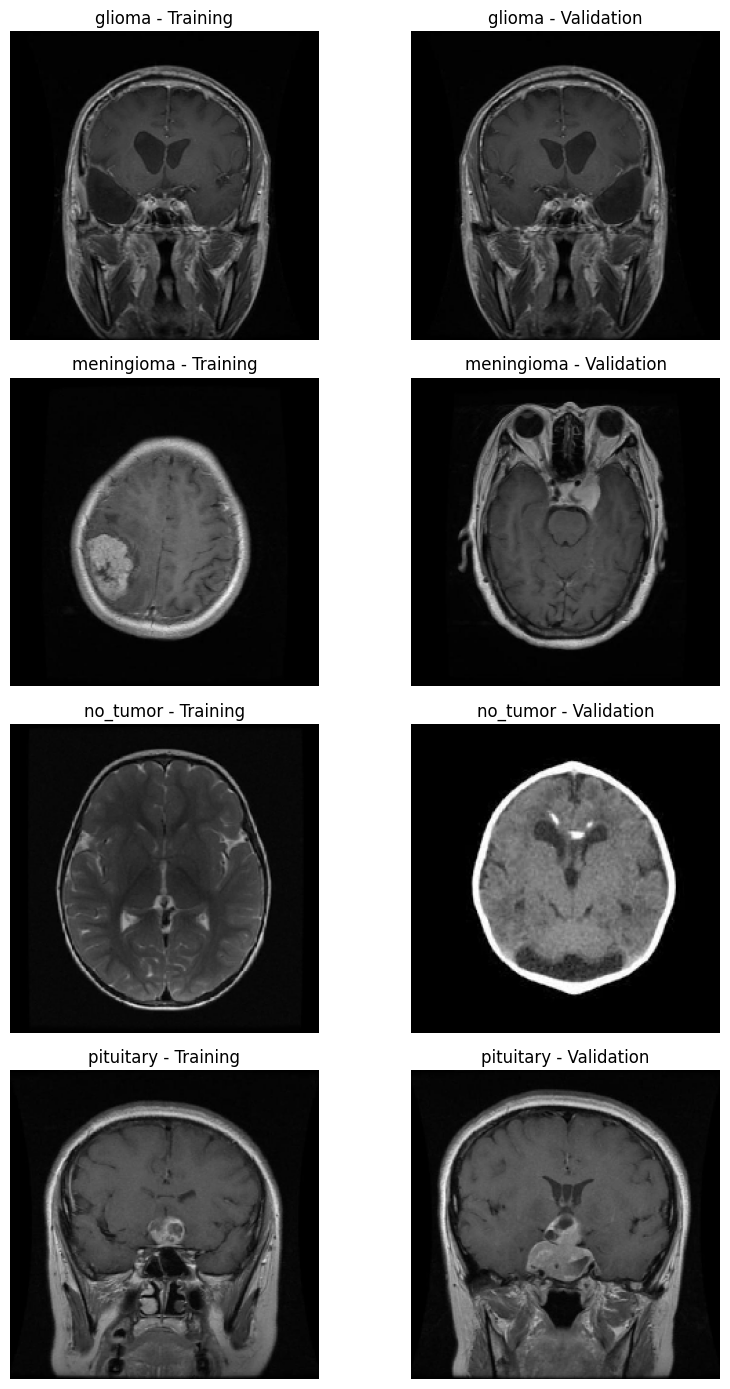

In [ ]:
# PURPOSE:
# Verify that all three dataset generators
# use exactly the same class-to-index mapping.

print("Training:", cnn_train_gen.class_indices)
print("Validation:", cnn_valid_gen.class_indices)
print("Testing:", cnn_test_gen.class_indices)

assert cnn_train_gen.class_indices == cnn_valid_gen.class_indices
assert cnn_train_gen.class_indices == cnn_test_gen.class_indices

print("SUCCESS: All class mappings match.")

# PURPOSE:
# Check whether MRI images are readable.
# Identify corrupted files and unusual image dimensions.

from PIL import Image
from collections import Counter

def inspect_images(folder):

    results = []
    corrupted = []

    for class_folder in folder.iterdir():

        if not class_folder.is_dir():
            continue

        for image_path in class_folder.rglob("*"):

            if image_path.suffix.lower() not in [
                ".jpg", ".jpeg", ".png", ".bmp"
            ]:
                continue

            try:
                with Image.open(image_path) as img:
                    results.append({
                        "class": class_folder.name,
                        "width": img.width,
                        "height": img.height,
                        "mode": img.mode
                    })

            except Exception:
                corrupted.append(str(image_path))

    return pd.DataFrame(results), corrupted


train_info, train_corrupted = inspect_images(TRAIN_DIR)
valid_info, valid_corrupted = inspect_images(VALID_DIR)

print("Training image dimensions:")
print(train_info[["width", "height"]].describe())

print("\nValidation image dimensions:")
print(valid_info[["width", "height"]].describe())

print("\nCorrupted training images:", len(train_corrupted))
print("Corrupted validation images:", len(valid_corrupted))



**What this block does:** This block displays randomly selected training and validation images for every class and checks exact file duplicates across splits.

**Why it matters:** The visual comparison can reveal obvious differences between splits; exact file hashing does not detect resized or near-duplicate images.

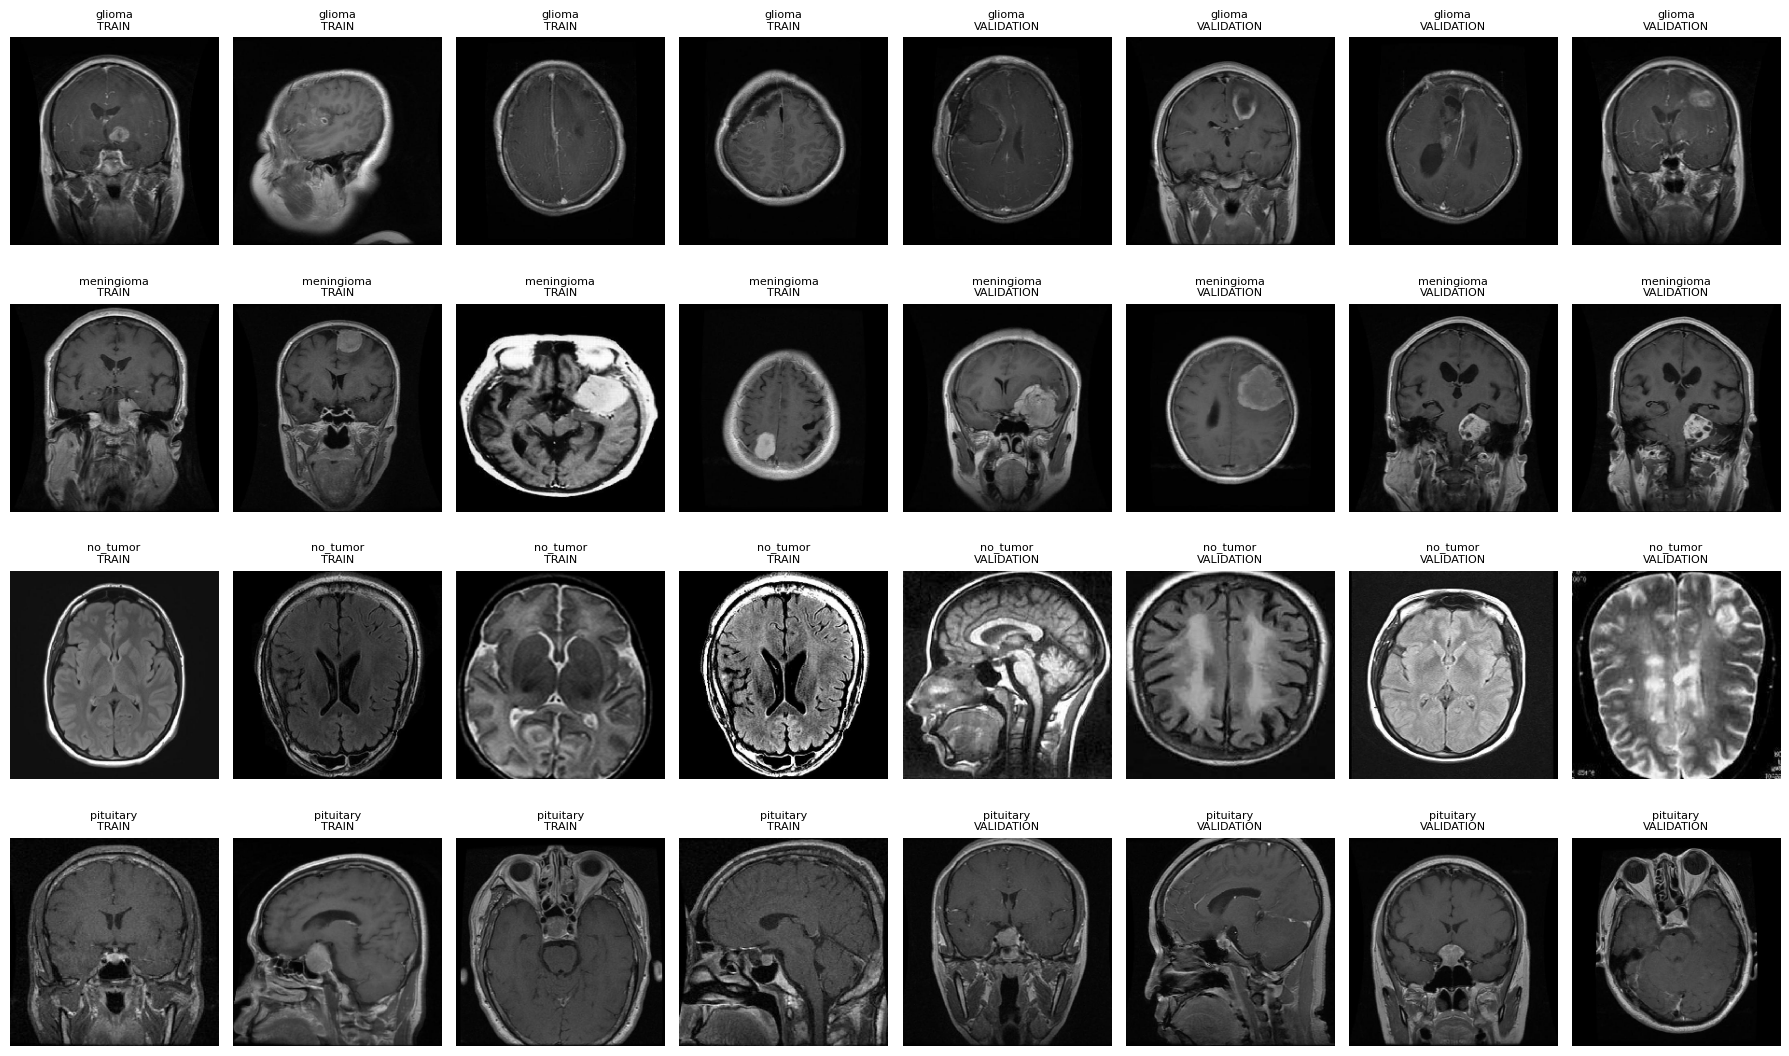

Train-validation exact duplicates: 0
Train-test exact duplicates: 0
Validation-test exact duplicates: 0


In [ ]:
# SECTION: RANDOM IMAGE DISTRIBUTION INSPECTION
# Purpose: Compare multiple training and validation samples.
# Expected result: Similar image characteristics within each class.

import random
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

random.seed(42)

fig, axes = plt.subplots(
    len(class_names), 8,
    figsize=(18, 11)
)

for row, class_name in enumerate(class_names):

    train_files = [
        p for p in (TRAIN_DIR / class_name).rglob("*")
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    valid_files = [
        p for p in (VALID_DIR / class_name).rglob("*")
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    train_samples = random.sample(train_files, min(4, len(train_files)))
    valid_samples = random.sample(valid_files, min(4, len(valid_files)))

    for col, image_path in enumerate(train_samples + valid_samples):

        img = load_img(image_path, target_size=(224, 224))

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        split = "TRAIN" if col < 4 else "VALIDATION"

        axes[row, col].set_title(
            f"{class_name}\n{split}",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# SECTION: DUPLICATE IMAGE DETECTION
# Purpose: Identify exact duplicate image files across splits.

import hashlib

def calculate_hash(path):

    with open(path, "rb") as file:
        return hashlib.md5(file.read()).hexdigest()


def collect_hashes(folder):

    hashes = {}

    for image_path in folder.rglob("*"):

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            continue

        hashes.setdefault(
            calculate_hash(image_path), []
        ).append(str(image_path))

    return hashes


train_hashes = collect_hashes(TRAIN_DIR)
valid_hashes = collect_hashes(VALID_DIR)
test_hashes = collect_hashes(TEST_DIR)

print("Train-validation exact duplicates:",
      len(set(train_hashes) & set(valid_hashes)))

print("Train-test exact duplicates:",
      len(set(train_hashes) & set(test_hashes)))

print("Validation-test exact duplicates:",
      len(set(valid_hashes) & set(test_hashes)))

**What this block does:** This block inspects the preprocessing settings and sample batches used by the CNN and validation generators.

**Why it matters:** It helps confirm image shapes and pixel-value ranges; training augmentation can make training batches differ from validation batches.

In [ ]:
# ============================================================
# SECTION: IMAGE PREPROCESSING AUDIT
# Purpose:
# 1. Inspect training and validation preprocessing.
# 2. Compare image normalization.
# 3. Check image and label batch shapes.
# 4. Identify preprocessing inconsistencies.
# ============================================================

def inspect_generator(generator, name):

    print(f"\n{'=' * 55}")
    print(f"{name} CONFIGURATION")
    print("=" * 55)

    datagen = generator.image_data_generator

    attributes = [
        "rescale",
        "rotation_range",
        "width_shift_range",
        "height_shift_range",
        "shear_range",
        "zoom_range",
        "horizontal_flip",
        "vertical_flip",
        "brightness_range",
        "preprocessing_function",
        "samplewise_center",
        "samplewise_std_normalization",
        "featurewise_center",
        "featurewise_std_normalization"
    ]

    for attribute in attributes:

        value = getattr(datagen, attribute, "Not available")

        print(f"{attribute}: {value}")

    print("\nImage size:", generator.image_shape)
    print("Class mapping:", generator.class_indices)
    print("Total images:", generator.samples)
    print("Batch size:", generator.batch_size)
    print("Shuffle:", generator.shuffle)


# Inspect both generators
inspect_generator(cnn_train_gen, "TRAINING")
inspect_generator(cnn_valid_gen, "VALIDATION")


# ============================================================
# SECTION: IMAGE BATCH COMPARISON
# Purpose: Compare actual pixel values and image dimensions.
# ============================================================

cnn_train_gen.reset()
cnn_valid_gen.reset()

x_train, y_train = next(iter(cnn_train_gen))
x_valid, y_valid = next(iter(cnn_valid_gen))

print("\n========== BATCH INFORMATION ==========")

print("Training image shape:", x_train.shape)
print("Validation image shape:", x_valid.shape)

print("Training pixel range:",
      x_train.min(), x_train.max())

print("Validation pixel range:",
      x_valid.min(), x_valid.max())

print("Training mean:", x_train.mean())
print("Validation mean:", x_valid.mean())

print("Training standard deviation:", x_train.std())
print("Validation standard deviation:", x_valid.std())

print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_valid.shape)


TRAINING CONFIGURATION
rescale: 0.00392156862745098
rotation_range: 12
width_shift_range: 0.08
height_shift_range: 0.08
shear_range: 0.0
zoom_range: [0.9, 1.1]
horizontal_flip: True
vertical_flip: False
brightness_range: None
preprocessing_function: None
samplewise_center: False
samplewise_std_normalization: False
featurewise_center: False
featurewise_std_normalization: False

Image size: (224, 224, 3)
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Total images: 1695
Batch size: 16
Shuffle: True

VALIDATION CONFIGURATION
rescale: 0.00392156862745098
rotation_range: 0
width_shift_range: 0.0
height_shift_range: 0.0
shear_range: 0.0
zoom_range: [1.0, 1.0]
horizontal_flip: False
vertical_flip: False
brightness_range: None
preprocessing_function: None
samplewise_center: False
samplewise_std_normalization: False
featurewise_center: False
featurewise_std_normalization: False

Image size: (224, 224, 3)
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 

**What this block does:** This block configures checkpointing, early stopping and learning-rate reduction, then trains the fresh Custom CNN.

**Why it matters:** The best checkpoint is saved using validation loss and reloaded after training so later evaluation uses the selected CNN weights.

In [ ]:
# ============================================================
# SECTION: CNN CALLBACK CONFIGURATION AND MODEL TRAINING
#
# PURPOSE:
# 1. Save the best CNN model.
# 2. Prevent unnecessary training.
# 3. Reduce learning rate when learning stagnates.
# 4. Handle class imbalance.
# 5. Restore the best validation checkpoint.
#
# IMPORTANT:
# This trains the existing freshly initialized cnn_model.
# It does not load previous project models.
# ============================================================

from pathlib import Path
import tensorflow as tf
from tensorflow import keras

# Ensure output directory exists
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_CNN_PATH = MODEL_DIR / "fresh_custom_cnn_exp2.keras"

# ------------------------------------------------------------
# CALLBACK 1: MODEL CHECKPOINT
# Saves the model with the lowest validation loss.
# ------------------------------------------------------------

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(BEST_CNN_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# ------------------------------------------------------------
# CALLBACK 2: EARLY STOPPING
# Stops training if validation loss does not improve.
# ------------------------------------------------------------

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------------------------
# CALLBACK 3: LEARNING RATE REDUCTION
# Reduces learning rate when validation loss stagnates.
# ------------------------------------------------------------

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.3,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

cnn_callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

# ------------------------------------------------------------
# MODEL TRAINING
# ------------------------------------------------------------

print("Starting fresh CNN training...")

cnn_history = cnn_model.fit(
    cnn_train_gen,
    validation_data=cnn_valid_gen,
    epochs=EPOCHS_CNN,
    class_weight=class_weights,
    callbacks=cnn_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# ------------------------------------------------------------

if not BEST_CNN_PATH.exists():
    raise FileNotFoundError(
        "Best CNN checkpoint was not created."
    )

cnn_model = keras.models.load_model(
    BEST_CNN_PATH,
    compile=False
)

print("\nBest CNN checkpoint loaded successfully.")
print("Model location:", BEST_CNN_PATH)
print("Completed epochs:", len(cnn_history.history["loss"]))
print(
    "Best validation accuracy:",
    max(cnn_history.history["val_accuracy"])
)
print(
    "Best validation loss:",
    min(cnn_history.history["val_loss"])
)

Starting fresh CNN training...
Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5352 - loss: 1.1534
Epoch 1: val_loss improved from None to 2.17869, saving model to c:\Users\Gokul\Downloads\Brain_Tumor_Project_\fresh_training_outputs\models\fresh_custom_cnn_exp2.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.6083 - loss: 1.0032 - val_accuracy: 0.3207 - val_loss: 2.1787 - learning_rate: 1.0000e-04
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7063 - loss: 0.7743
Epoch 2: val_loss did not improve from 2.17869
106/106 ━━━━━━━━━━━━━━━━━━━━ 387s 4s/step - accuracy: 0.7103 - loss: 0.7595 - val_accuracy: 0.3227 - val_loss: 2.4178 - learning_rate: 1.0000e-04
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7498 - loss: 0.6974
Epoch 3: val_loss improved from 2.17869 to 2.10517, saving model to c:\Users\Gokul\Downloads\Brain_Tumor_Project_\fresh_training_outputs\models\fresh_custom_cnn_exp2.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 464s 

**What this block does:** This block compiles the trained Custom CNN and evaluates it on the separate test generator.

**Why it matters:** It reports test loss and accuracy; run this only after the best CNN checkpoint has been loaded.

In [ ]:
# Compile the loaded Experiment 2 model
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Experiment 2 model compiled successfully.")

# Evaluate on the untouched test dataset
test_loss, test_accuracy = cnn_model.evaluate(
    cnn_test_gen,
    verbose=1
)

print("\nEXPERIMENT 2 TEST RESULTS")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Experiment 2 model compiled successfully.
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 336ms/step - accuracy: 0.8496 - loss: 0.4549

EXPERIMENT 2 TEST RESULTS
Test Loss: 0.4549
Test Accuracy: 84.96%


**What this block does:** This block generates predictions for all Custom CNN test images and prints precision, recall and F1-score by class.

**Why it matters:** The confusion matrix shows which actual classes are being confused with other predicted classes.

16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 364ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.8941    0.9500    0.9212        80
  meningioma     0.8837    0.6032    0.7170        63
    no_tumor     0.7857    0.8980    0.8381        49
   pituitary     0.8226    0.9444    0.8793        54

    accuracy                         0.8496       246
   macro avg     0.8465    0.8489    0.8389       246
weighted avg     0.8542    0.8496    0.8432       246



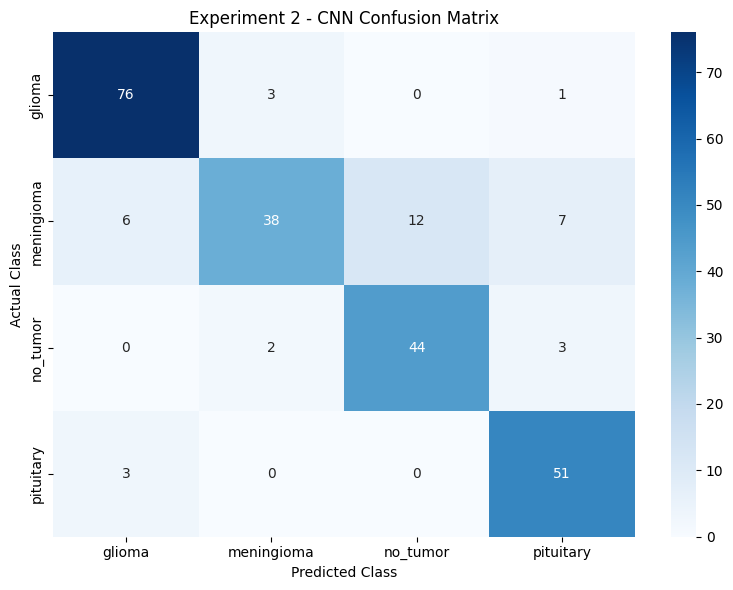

In [ ]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure test generator starts from the first image
cnn_test_gen.reset()

# Predict all test images
predictions = cnn_model.predict(cnn_test_gen, verbose=1)

# Actual and predicted class indices
y_true = cnn_test_gen.classes
y_pred = np.argmax(predictions, axis=1)

# Class names
labels = list(cnn_test_gen.class_indices.keys())

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=labels,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Experiment 2 - CNN Confusion Matrix")
plt.tight_layout()
plt.show()

**What this block does:** This block compares the Custom CNN's predicted labels with the true test labels and lists every incorrect prediction.

**Why it matters:** It also summarizes the error pairs and highlights the images whose actual class is meningioma.

In [ ]:
import numpy as np
import pandas as pd

# Reset test generator to start from the first image
cnn_test_gen.reset()

# Generate predictions
predictions = cnn_model.predict(cnn_test_gen, verbose=1)

# Actual and predicted class numbers
y_true = cnn_test_gen.classes
y_pred = np.argmax(predictions, axis=1)

# Class names
class_names = list(cnn_test_gen.class_indices.keys())

# Find incorrect predictions
wrong_indices = np.where(y_true != y_pred)[0]

# Prepare error details
errors = []

for i in wrong_indices:
    errors.append({
        "Image": cnn_test_gen.filenames[i],
        "Actual": class_names[y_true[i]],
        "Predicted": class_names[y_pred[i]],
        "Confidence": round(float(predictions[i][y_pred[i]]) * 100, 2)
    })

error_df = pd.DataFrame(errors)

print("Total incorrect predictions:", len(error_df))
print("\nMisclassification summary:")
print(error_df.groupby(["Actual", "Predicted"]).size())

print("\nMeningioma misclassified images:")
meningioma_errors = error_df[
    error_df["Actual"] == "meningioma"
]

print(meningioma_errors.to_string(index=False))

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 441ms/step
Total incorrect predictions: 37

Misclassification summary:
Actual      Predicted 
glioma      meningioma     3
            pituitary      1
meningioma  glioma         6
            no_tumor      12
            pituitary      7
no_tumor    meningioma     2
            pituitary      3
pituitary   glioma         3
dtype: int64

Meningioma misclassified images:
                                                            Image     Actual Predicted  Confidence
meningioma\Tr-me_0010_jpg.rf.64b09cdfd6ad5f8352e473a7d3015dba.jpg meningioma    glioma       59.40
meningioma\Tr-me_0059_jpg.rf.a7ddf325d1b4508eb5e9048c5cb9133d.jpg meningioma    glioma       44.82
meningioma\Tr-me_0084_jpg.rf.8da0909e5ac2b199b846a7b8a7ae18d0.jpg meningioma pituitary       69.22
meningioma\Tr-me_0088_jpg.rf.e61e56a612e513fe2556d7a23c910913.jpg meningioma    glioma       50.11
meningioma\Tr-me_0143_jpg.rf.05f1fad0d3ae0848b844e86f0f0e8af6.jpg meningioma    glioma       49.83
men

**What this block does:** This block displays up to twelve incorrectly classified meningioma test images.

**Why it matters:** Inspect these examples for visual patterns, but do not assume that image appearance alone explains why the model made an error.

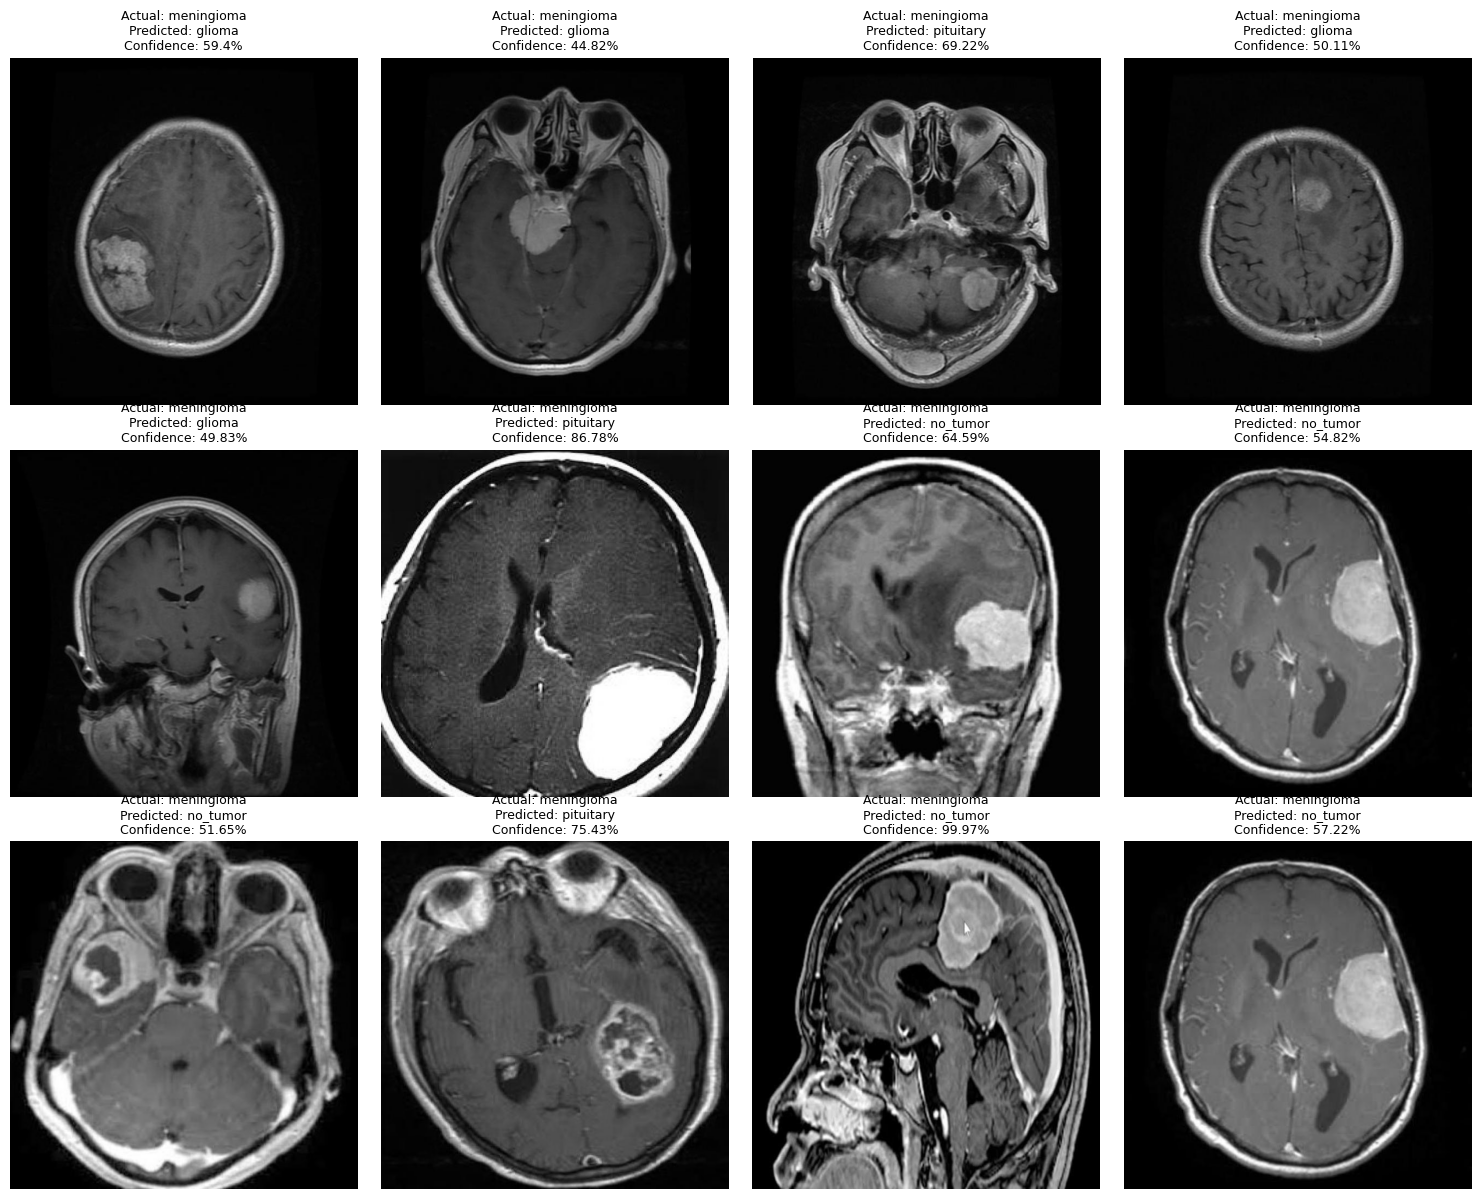

In [ ]:
import matplotlib.pyplot as plt
import os
import numpy as np

# Display the first 12 incorrectly classified meningioma images
sample_errors = meningioma_errors.head(12)

plt.figure(figsize=(15, 12))

for position, (_, row) in enumerate(sample_errors.iterrows()):
    image_path = os.path.join(
        cnn_test_gen.directory,
        row["Image"]
    )

    image = plt.imread(image_path)

    plt.subplot(3, 4, position + 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {row['Actual']}\n"
        f"Predicted: {row['Predicted']}\n"
        f"Confidence: {row['Confidence']}%",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

**What this block does:** This block displays examples of correctly and incorrectly classified meningioma images side by side.

**Why it matters:** The comparison supports qualitative error review and should be interpreted alongside the numerical evaluation metrics.

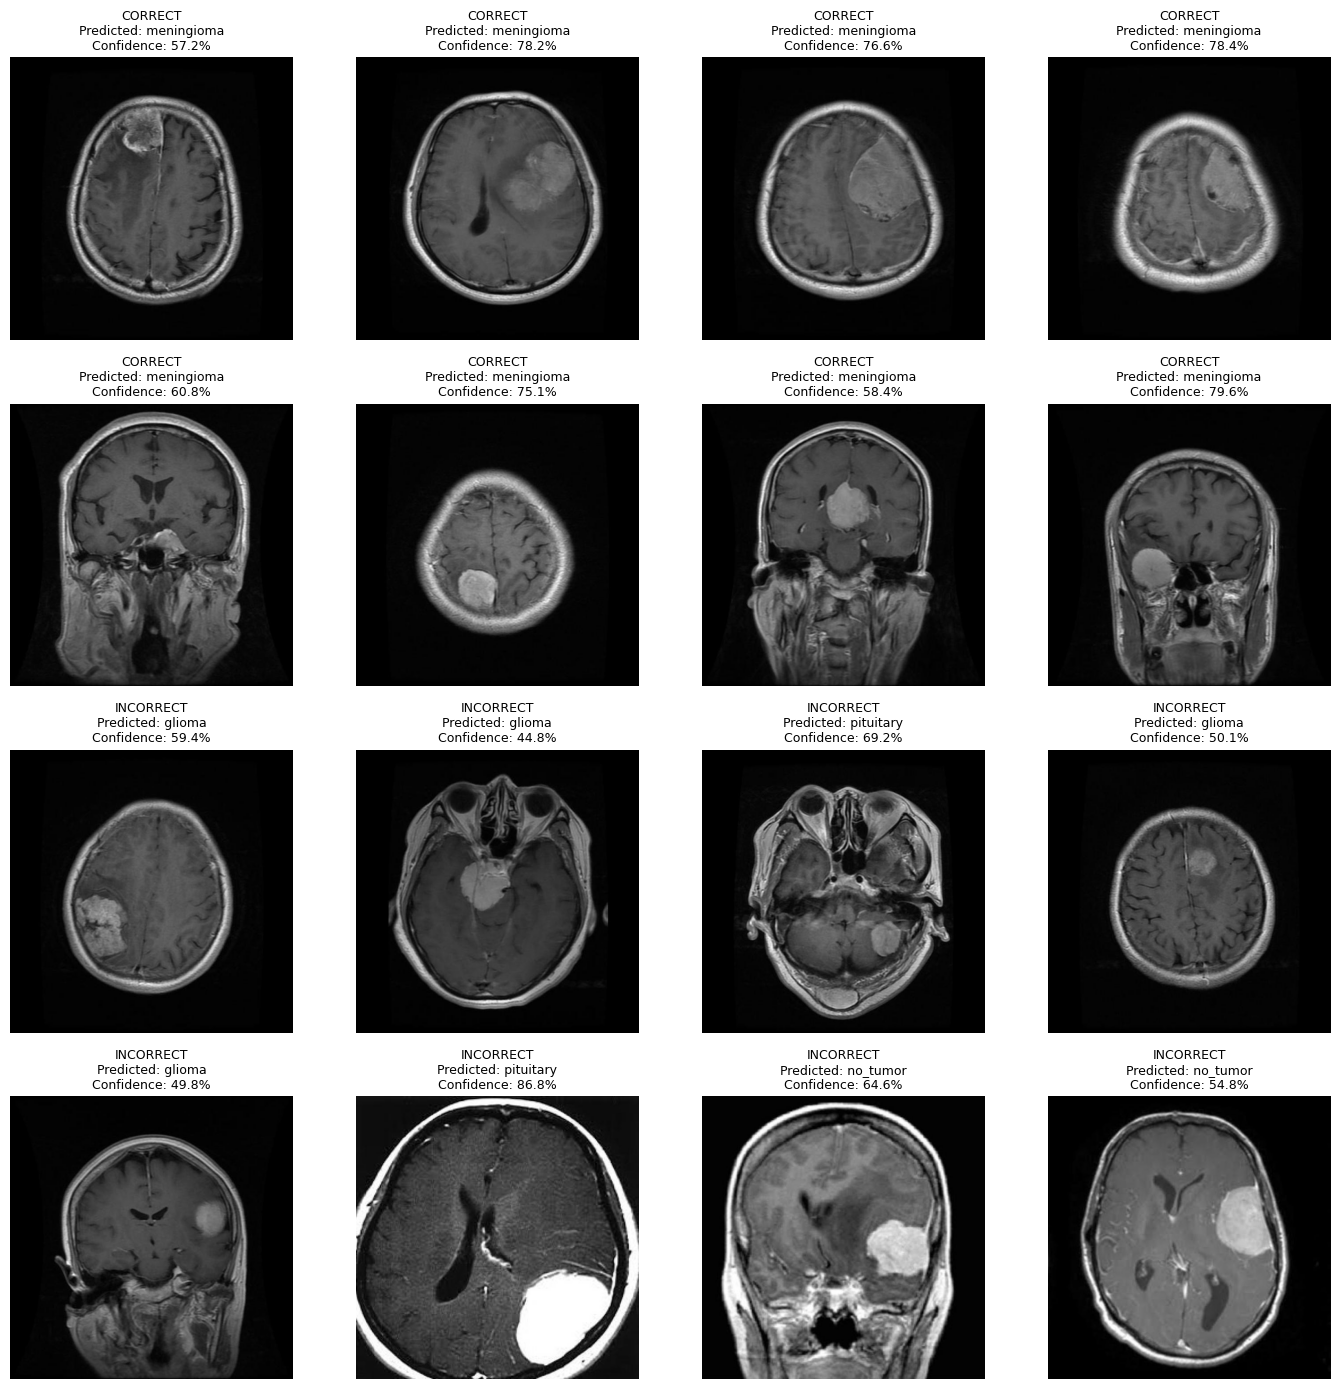

In [ ]:
import matplotlib.pyplot as plt
import os

# Correctly classified meningioma images
correct_indices = np.where(
    (y_true == 1) & (y_pred == 1)
)[0]

# Misclassified meningioma images
wrong_indices = np.where(
    (y_true == 1) & (y_pred != 1)
)[0]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))

# First 8 correct and 8 incorrect examples
selected = list(correct_indices[:8]) + list(wrong_indices[:8])

for i, idx in enumerate(selected):
    image_path = os.path.join(
        cnn_test_gen.directory,
        cnn_test_gen.filenames[idx]
    )

    image = plt.imread(image_path)

    axes[i // 4, i % 4].imshow(image, cmap="gray")

    status = "CORRECT" if y_pred[idx] == 1 else "INCORRECT"

    axes[i // 4, i % 4].set_title(
        f"{status}\n"
        f"Predicted: {class_names[y_pred[idx]]}\n"
        f"Confidence: {predictions[idx][y_pred[idx]]*100:.1f}%",
        fontsize=9
    )

    axes[i // 4, i % 4].axis("off")

plt.tight_layout()
plt.show()

**What this block does:** This block performs a deeper review of the Custom CNN's actual meningioma test cases, including image brightness, contrast and prediction scores.

**Why it matters:** It saves a CSV report and plots diagnostic summaries; these are exploratory associations, not proof of the cause of a misclassification.

16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 455ms/step

========== OVERALL TEST REPORT ==========
              precision    recall  f1-score   support

      glioma     0.8941    0.9500    0.9212        80
  meningioma     0.8837    0.6032    0.7170        63
    no_tumor     0.7857    0.8980    0.8381        49
   pituitary     0.8226    0.9444    0.8793        54

    accuracy                         0.8496       246
   macro avg     0.8465    0.8489    0.8389       246
weighted avg     0.8542    0.8496    0.8432       246


========== MENINGIOMA ERROR SUMMARY ==========
Predicted
glioma         6
meningioma    38
no_tumor      12
pituitary      7
dtype: int64

Correct: 38
Incorrect: 25

========== IMAGE QUALITY COMPARISON ==========
         Mean_Brightness  Contrast_Std  Width  Height  Confidence  \
Correct                                                             
False              58.29         53.61  640.0   640.0       65.63   
True               37.88         46.55  640.0   640.0       

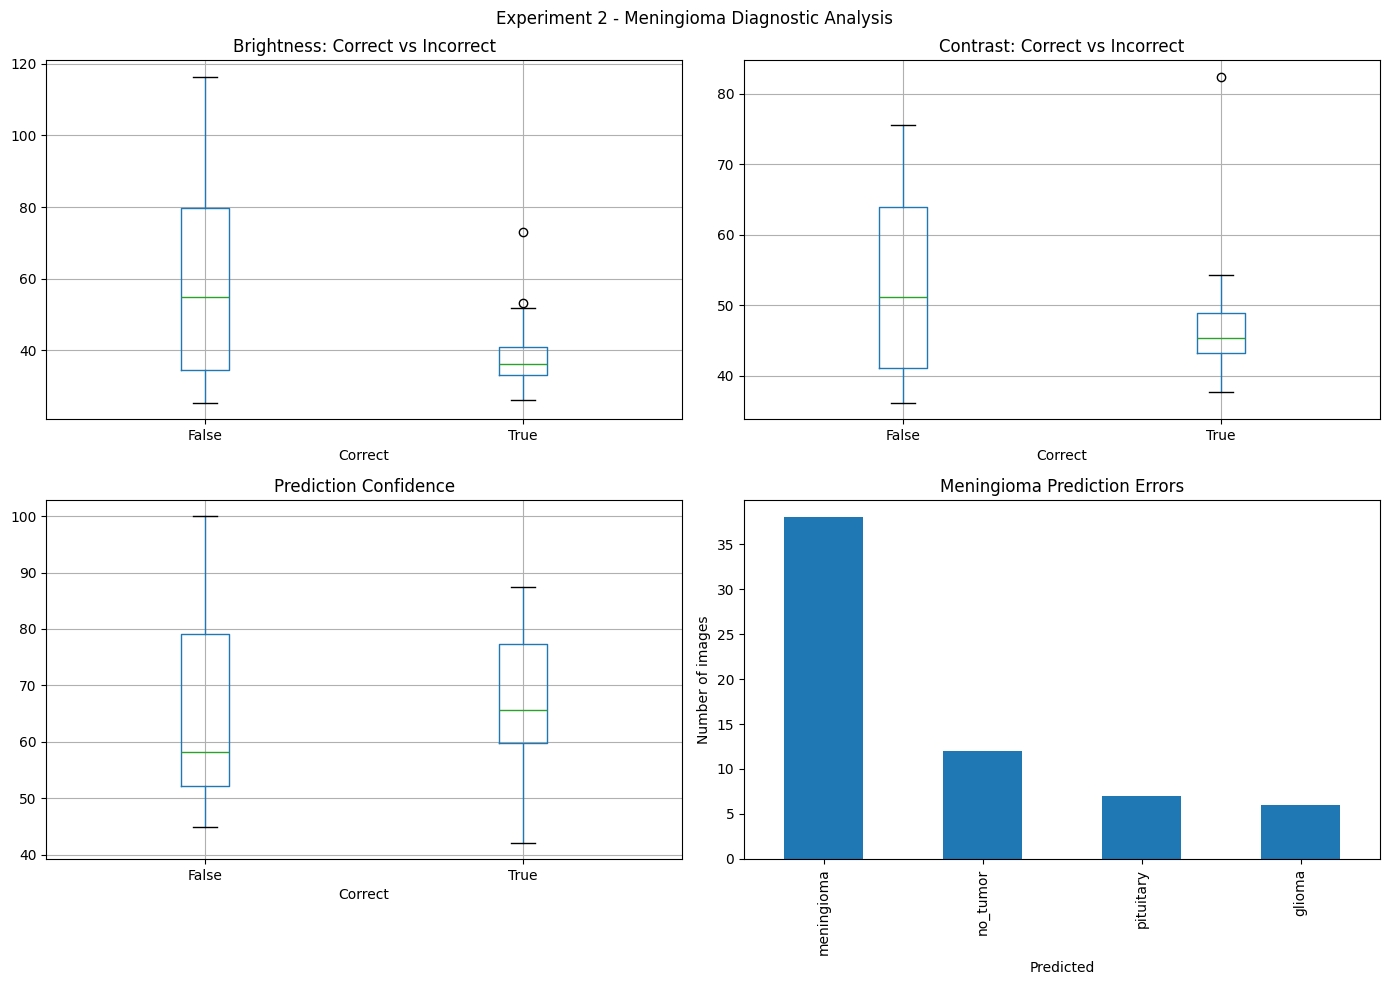


========== REPORT SAVED ==========
File: c:\Users\Gokul\Downloads\Brain_Tumor_Project_\meningioma_diagnostic_report.csv
Total images analysed: 63
Diagnostic investigation completed.


In [ ]:

# ============================================================
# COMPLETE MENINGIOMA ERROR INVESTIGATION
# Uses existing Experiment 2 model - NO RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report

# 1. Generate predictions
cnn_test_gen.reset()
predictions = cnn_model.predict(cnn_test_gen, verbose=1)

y_true = cnn_test_gen.classes
y_pred = np.argmax(predictions, axis=1)
class_names = list(cnn_test_gen.class_indices.keys())

# 2. Analyse every actual meningioma image
results = []

for idx in np.where(y_true == 1)[0]:

    path = cnn_test_gen.filepaths[idx]

    with Image.open(path) as img:
        gray = np.array(img.convert("L"))

        results.append({
            "Image": cnn_test_gen.filenames[idx],
            "Actual": "meningioma",
            "Predicted": class_names[y_pred[idx]],
            "Correct": bool(y_pred[idx] == 1),
            "Confidence": round(float(predictions[idx].max()) * 100, 2),
            "Meningioma_Probability": round(float(predictions[idx][1]) * 100, 2),
            "Width": img.width,
            "Height": img.height,
            "Mean_Brightness": round(float(gray.mean()), 2),
            "Contrast_Std": round(float(gray.std()), 2)
        })

df = pd.DataFrame(results)

# 3. Print classification summary
print("\n========== OVERALL TEST REPORT ==========")
print(classification_report(
    y_true, y_pred, target_names=class_names, digits=4
))

print("\n========== MENINGIOMA ERROR SUMMARY ==========")
print(df.groupby("Predicted").size())
print("\nCorrect:", df["Correct"].sum())
print("Incorrect:", (~df["Correct"]).sum())

# 4. Compare image characteristics
print("\n========== IMAGE QUALITY COMPARISON ==========")

comparison = df.groupby("Correct")[
    ["Mean_Brightness", "Contrast_Std", "Width", "Height",
     "Confidence", "Meningioma_Probability"]
].mean().round(2)

print(comparison)

# 5. Confidence analysis
print("\n========== CONFIDENCE ANALYSIS ==========")

for threshold in [50, 60, 70, 80, 90]:
    accepted = df[df["Confidence"] >= threshold]
    print(
        f"Threshold {threshold}%: "
        f"{len(accepted)} images, "
        f"{accepted['Correct'].mean()*100 if len(accepted) else 0:.2f}% accuracy"
    )

# 6. Generate diagnostic charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Brightness comparison
df.boxplot(column="Mean_Brightness", by="Correct", ax=axes[0, 0])
axes[0, 0].set_title("Brightness: Correct vs Incorrect")

# Contrast comparison
df.boxplot(column="Contrast_Std", by="Correct", ax=axes[0, 1])
axes[0, 1].set_title("Contrast: Correct vs Incorrect")

# Confidence distribution
df.boxplot(column="Confidence", by="Correct", ax=axes[1, 0])
axes[1, 0].set_title("Prediction Confidence")

# Prediction distribution
df["Predicted"].value_counts().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Meningioma Prediction Errors")
axes[1, 1].set_ylabel("Number of images")

plt.suptitle("Experiment 2 - Meningioma Diagnostic Analysis")
plt.tight_layout()
plt.show()

# 7. Save complete report
output_file = "meningioma_diagnostic_report.csv"
df.to_csv(output_file, index=False)

print("\n========== REPORT SAVED ==========")
print("File:", os.path.abspath(output_file))
print("Total images analysed:", len(df))
print("Diagnostic investigation completed.")


Experiment 3 – Fresh ResNet50 Transfer Learning with Improved MRI Preprocessing.

**What this block does:** This block trains a new ResNet50 transfer-learning model using generic ImageNet weights and the project's four MRI classes.

**Why it matters:** It trains a new classification head, fine-tunes the selected layers, and saves the best checkpoint and validation reports separately from the Custom CNN.

TensorFlow version: 2.21.0
Dataset: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour
Output: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50
Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.

Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Training images: 1695
Validation images: 502
Test images: 246

Class weights: {0: 0.7513297872340425, 1: 1.183659217877095, 2: 1.2649253731343284, 3: 0.9674657534246576}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 30s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)


========== PHASE 1: FROZEN RESNET50 ==========
Epoch 1/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5337 - loss: 1.4480
Epoch 1: val_loss improved from None to 0.50941, saving model to C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\models\best_resnet50_exp3.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 324s 3s/step - accuracy: 0.6566 - loss: 1.0158 - val_accuracy: 0.8068 - val_loss: 0.5094 - learning_rate: 1.0000e-04
Epoch 2/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8224 - loss: 0.5127
Epoch 2: val_loss improved from 0.50941 to 0.36556, saving model to C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\models\best_resnet50_exp3.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.8307 - loss: 0.4805 - val_accuracy: 0.8865 - val_loss: 0.3656 - learning_rate: 1.0000e-04
Epoch 3/8
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8467 - loss: 0.3928
Epoch 3: val_loss improved from 0.36556 to 0.32348, saving model to C:\Users\

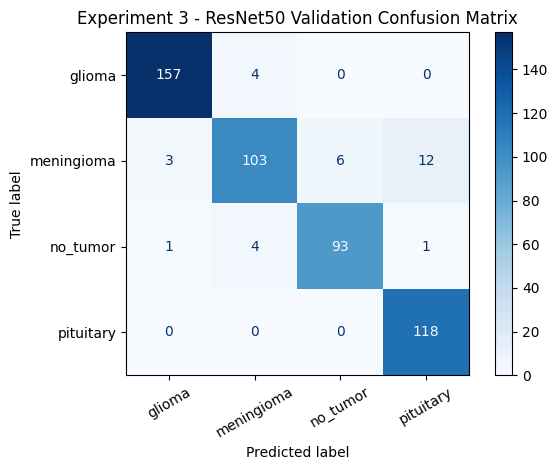


========== VALIDATION CONFIDENCE ==========
50% threshold | Accepted: 502/502 | Coverage: 100.00% | Accuracy among accepted: 93.82%
60% threshold | Accepted: 494/502 | Coverage: 98.41% | Accuracy among accepted: 94.74%
70% threshold | Accepted: 483/502 | Coverage: 96.22% | Accuracy among accepted: 95.65%
80% threshold | Accepted: 472/502 | Coverage: 94.02% | Accuracy among accepted: 96.19%
90% threshold | Accepted: 441/502 | Coverage: 87.85% | Accuracy among accepted: 97.05%


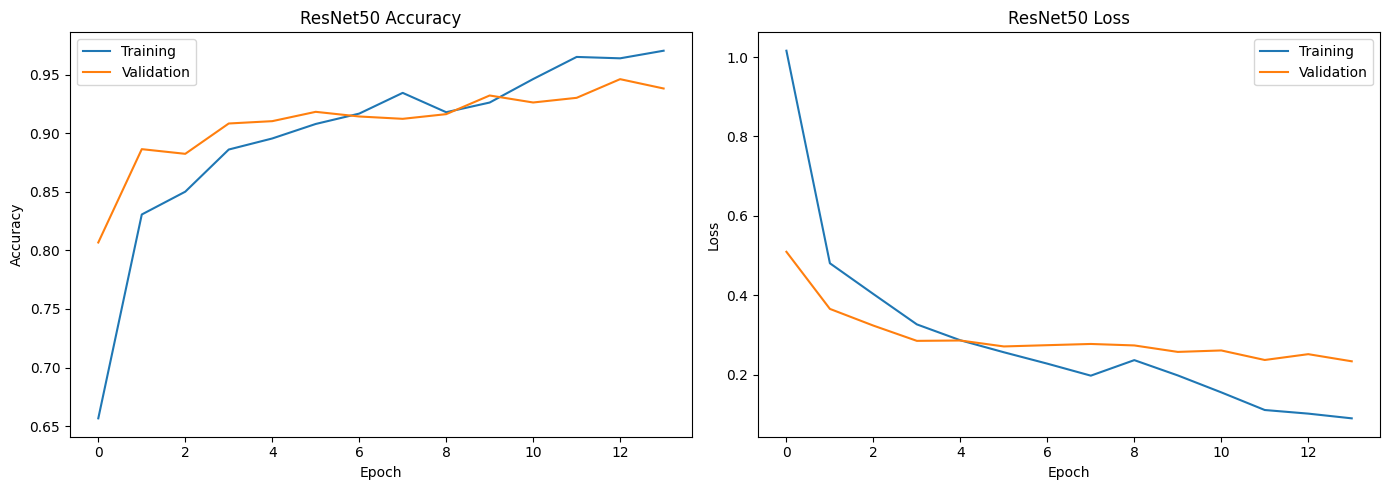


EXPERIMENT 3 COMPLETED
Model: Fresh ResNet50
Validation accuracy: 93.82 %
Validation macro F1: 93.47 %
Best model: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\models\best_resnet50_exp3.keras
Reports folder: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50

Test set has NOT been evaluated in this experiment.
Select the best model using validation results first.


In [ ]:

# ================================================================
# EXPERIMENT 3: FRESH RESNET50 TRANSFER LEARNING
# Brain Tumor MRI Classification - 4 Classes
# TensorFlow / Keras
#
# Does NOT load previous project checkpoints.
# Does NOT overwrite Experiment 2.
# ================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import (
    ResNet50,
    preprocess_input
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
HEAD_EPOCHS = 8
FINETUNE_EPOCHS = 6

tf.keras.utils.set_random_seed(SEED)

# CHANGE THIS PATH ONLY IF YOUR DATASET IS IN A DIFFERENT LOCATION
DATASET_DIR = Path(
    r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour"
)

TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"
TEST_DIR = DATASET_DIR / "test"

# Save Experiment 3 separately
OUTPUT_DIR = DATASET_DIR.parent / "experiment3_resnet50"
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_resnet50_exp3.keras"

# Check dataset folders
for folder in [TRAIN_DIR, VALID_DIR, TEST_DIR]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {folder}\n"
            "Please correct DATASET_DIR."
        )

print("TensorFlow version:", tf.__version__)
print("Dataset:", DATASET_DIR)
print("Output:", OUTPUT_DIR)

# ------------------------------------------------
# 2. IMAGE PREPROCESSING AND AUGMENTATION
# ------------------------------------------------

# ResNet50 requires its own preprocessing function.
# Do NOT combine this with rescale=1./255.

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.08,
    horizontal_flip=False,
    fill_mode="nearest"
)

valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

valid_gen = valid_datagen.flow_from_directory(
    str(VALID_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    str(TEST_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_names = list(train_gen.class_indices.keys())
NUM_CLASSES = len(class_names)

print("\nClass mapping:", train_gen.class_indices)
print("Training images:", train_gen.samples)
print("Validation images:", valid_gen.samples)
print("Test images:", test_gen.samples)

assert train_gen.class_indices == valid_gen.class_indices
assert train_gen.class_indices == test_gen.class_indices
assert NUM_CLASSES == 4

# ------------------------------------------------
# 3. HANDLE CLASS IMBALANCE
# ------------------------------------------------

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:", class_weights)

# ------------------------------------------------
# 4. BUILD A COMPLETELY FRESH RESNET50 MODEL
# ------------------------------------------------

# ImageNet weights are general-purpose pretrained weights.
# No previous project model checkpoint is loaded.

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

resnet_model = keras.Model(inputs, outputs)

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

# ------------------------------------------------
# 5. CALLBACKS
# ------------------------------------------------

def make_callbacks():

    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(BEST_MODEL_PATH),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

# ------------------------------------------------
# 6. PHASE 1: TRAIN CLASSIFICATION HEAD
# ------------------------------------------------

print("\n========== PHASE 1: FROZEN RESNET50 ==========")

history_head = resnet_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
    verbose=1
)

# ------------------------------------------------
# 7. PHASE 2: FINE-TUNE FINAL RESNET50 LAYERS
# ------------------------------------------------

print("\n========== PHASE 2: FINE-TUNING ==========")

base_model.trainable = True

# Freeze earlier layers and train only the final 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = resnet_model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=FINETUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
    verbose=1
)

# ------------------------------------------------
# 8. LOAD BEST VALIDATION CHECKPOINT
# ------------------------------------------------

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError("Best ResNet50 checkpoint was not created.")

best_resnet = keras.models.load_model(
    str(BEST_MODEL_PATH),
    compile=False
)

best_resnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------
# 9. VALIDATION EVALUATION
# ------------------------------------------------

print("\n========== VALIDATION EVALUATION ==========")

valid_gen.reset()

val_loss, val_accuracy = best_resnet.evaluate(
    valid_gen,
    verbose=1
)

valid_probabilities = best_resnet.predict(
    valid_gen,
    verbose=1
)

y_val_true = valid_gen.classes
y_val_pred = np.argmax(valid_probabilities, axis=1)

print("\nValidation accuracy:", round(val_accuracy * 100, 2), "%")
print(
    "Validation macro F1:",
    round(f1_score(y_val_true, y_val_pred, average="macro") * 100, 2),
    "%"
)

print("\nValidation classification report:")
report = classification_report(
    y_val_true,
    y_val_pred,
    target_names=class_names,
    digits=4,
    output_dict=True,
    zero_division=0
)

print(classification_report(
    y_val_true,
    y_val_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# ------------------------------------------------
# 10. VALIDATION CONFUSION MATRIX
# ------------------------------------------------

cm = confusion_matrix(
    y_val_true,
    y_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Experiment 3 - ResNet50 Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. VALIDATION CONFIDENCE ANALYSIS
# ------------------------------------------------

val_confidence = np.max(valid_probabilities, axis=1) * 100

print("\n========== VALIDATION CONFIDENCE ==========")

for threshold in [50, 60, 70, 80, 90]:
    accepted = val_confidence >= threshold

    if accepted.sum() > 0:
        accepted_accuracy = accuracy_score(
            y_val_true[accepted],
            y_val_pred[accepted]
        )

        print(
            f"{threshold}% threshold | "
            f"Accepted: {accepted.sum()}/{len(y_val_true)} | "
            f"Coverage: {accepted.mean()*100:.2f}% | "
            f"Accuracy among accepted: {accepted_accuracy*100:.2f}%"
        )
    else:
        print(f"{threshold}% threshold | No accepted predictions")

# ------------------------------------------------
# 12. SAVE VALIDATION REPORT
# ------------------------------------------------

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    OUTPUT_DIR / "resnet50_validation_report.csv"
)

validation_predictions = pd.DataFrame({
    "Image": valid_gen.filenames,
    "Actual": [class_names[i] for i in y_val_true],
    "Predicted": [class_names[i] for i in y_val_pred],
    "Confidence": np.round(val_confidence, 2),
    "Correct": y_val_true == y_val_pred
})

validation_predictions.to_csv(
    OUTPUT_DIR / "resnet50_validation_predictions.csv",
    index=False
)

# ------------------------------------------------
# 13. PLOT TRAINING HISTORY
# ------------------------------------------------

train_acc = (
    history_head.history["accuracy"]
    + history_finetune.history["accuracy"]
)

val_acc = (
    history_head.history["val_accuracy"]
    + history_finetune.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"]
    + history_finetune.history["loss"]
)

val_loss_history = (
    history_head.history["val_loss"]
    + history_finetune.history["val_loss"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_acc, label="Training")
axes[0].plot(val_acc, label="Validation")
axes[0].set_title("ResNet50 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(train_loss, label="Training")
axes[1].plot(val_loss_history, label="Validation")
axes[1].set_title("ResNet50 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------

print("\n==========================================")
print("EXPERIMENT 3 COMPLETED")
print("==========================================")

print("Model: Fresh ResNet50")
print("Validation accuracy:", round(val_accuracy * 100, 2), "%")
print(
    "Validation macro F1:",
    round(f1_score(y_val_true, y_val_pred, average="macro") * 100, 2),
    "%"
)

print("Best model:", BEST_MODEL_PATH)
print("Reports folder:", OUTPUT_DIR)

print("\nTest set has NOT been evaluated in this experiment.")
print("Select the best model using validation results first.")
print("==========================================")


Section 8.1 – Understanding final model evaluation

# SECTION 8: FINAL TEST EVALUATION OF RESNET50

## 8.1 Purpose

In this section, we evaluate our trained ResNet50 model
using the separate test dataset.

The test dataset contains 246 MRI images.

These images were not used to train the model or select
its best checkpoint.

## 8.2 Why do we need a test dataset?

Training accuracy tells us how well the model learns
from training images.

Validation accuracy helps us monitor model performance
and select the best checkpoint.

Test accuracy measures performance on a separate
dataset that was not used during model development.

This gives us a more independent estimate of
how the model performs on unseen images.

## 8.3 What is model evaluation?

Model evaluation measures the quality of predictions
using actual test labels.

We will calculate:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. Confusion matrix
6. Confidence distribution

## 8.4 What is a confusion matrix?

A confusion matrix compares actual classes against
predicted classes.

The diagonal cells represent correct predictions.

The other cells represent incorrect predictions.

It helps us identify which tumor categories
the model confuses.

## 8.5 Important evaluation rule

We must not use test results to change model weights,
tune hyperparameters or repeatedly select models.

The test dataset is reserved for final evaluation.

## 8.6 Expected outcome

We will understand:

- Overall test accuracy.
- Performance of each MRI category.
- Meningioma classification performance.
- Incorrectly classified image names.
- Reliability of predictions above 80% confidence.

This is an educational image-classification evaluation,
not a clinically validated medical diagnostic assessment.


**What this block does:** This block loads the saved best ResNet50 checkpoint from Experiment 3 and compiles it for evaluation.

**Why it matters:** It verifies the model's input/output shapes and parameter count before running the final test evaluation.

In [ ]:

# ==================================================
# SECTION 8.2: LOAD BEST RESNET50 MODEL
# ==================================================

from pathlib import Path
from tensorflow import keras

# Path to the saved Experiment 3 model
MODEL_PATH = Path(
    r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\models\best_resnet50_exp3.keras"
)

# Verify model file
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"ResNet50 model not found: {MODEL_PATH}"
    )

# Load the trained model
best_resnet = keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

# Compile for evaluation
best_resnet.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model loaded successfully.")
print("Model input:", best_resnet.input_shape)
print("Model output:", best_resnet.output_shape)
print("Model parameters:", best_resnet.count_params())
print("Model location:", MODEL_PATH)


ResNet50 model loaded successfully.
Model input: (None, 224, 224, 3)
Model output: (None, 4)
Model parameters: 24121476
Model location: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\models\best_resnet50_exp3.keras


**What this block does:** This block evaluates ResNet50 on the test generator and calculates accuracy, class-level metrics and a confusion matrix.

**Why it matters:** The test generator is kept in a fixed order so each prediction remains aligned with its actual label and filename.

16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.9268 - loss: 0.2485
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step 

========== RESNET50 FINAL TEST RESULTS ==========
Test Loss: 0.2485
Test Accuracy: 92.68%
Macro F1-score: 92.01%
Weighted F1-score: 92.55%

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      glioma     0.9639    1.0000    0.9816        80
  meningioma     0.8852    0.8571    0.8710        63
    no_tumor     0.9756    0.8163    0.8889        49
   pituitary     0.8852    1.0000    0.9391        54

    accuracy                         0.9268       246
   macro avg     0.9275    0.9184    0.9201       246
weighted avg     0.9288    0.9268    0.9255       246



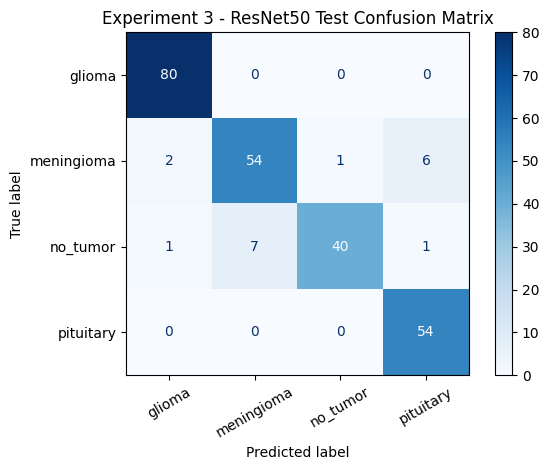


Final test evaluation completed.


In [ ]:

# ==================================================
# SECTION 8.3: FINAL TEST EVALUATION
# ==================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

import matplotlib.pyplot as plt

# Reset test generator
test_gen.reset()

# Evaluate loss and accuracy
test_loss, test_accuracy = best_resnet.evaluate(
    test_gen,
    verbose=1
)

# Generate predictions
test_gen.reset()

test_probabilities = best_resnet.predict(
    test_gen,
    verbose=1
)

# Actual and predicted classes
y_test_true = test_gen.classes

y_test_pred = np.argmax(
    test_probabilities,
    axis=1
)

# Class names
class_names = list(test_gen.class_indices.keys())

# Overall metrics
test_macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted"
)

print("\n========== RESNET50 FINAL TEST RESULTS ==========")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-score: {test_macro_f1 * 100:.2f}%")
print(f"Weighted F1-score: {test_weighted_f1 * 100:.2f}%")

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test_true,
    y_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Experiment 3 - ResNet50 Test Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nFinal test evaluation completed.")


**What this block does:** This block measures how many test predictions meet several softmax-score thresholds and calculates accuracy among those accepted predictions.

**Why it matters:** It also saves a row-by-row CSV containing the image name, actual class, predicted class, score and correctness.

In [ ]:

# ==================================================
# SECTION 8.4: TEST CONFIDENCE ANALYSIS
# ==================================================

# Highest predicted probability for each image
test_confidence = (
    np.max(test_probabilities, axis=1) * 100
)

# Check different confidence thresholds
print("\n========== TEST CONFIDENCE ANALYSIS ==========")

for threshold in [50, 60, 70, 80, 90]:

    accepted = test_confidence >= threshold

    accepted_count = accepted.sum()

    coverage = accepted_count / len(y_test_true) * 100

    if accepted_count > 0:

        accepted_accuracy = accuracy_score(
            y_test_true[accepted],
            y_test_pred[accepted]
        ) * 100

        print(
            f"\nThreshold: {threshold}%"
            f"\nAccepted: {accepted_count}/{len(y_test_true)}"
            f"\nCoverage: {coverage:.2f}%"
            f"\nAccuracy among accepted: {accepted_accuracy:.2f}%"
        )

    else:
        print(f"\nThreshold {threshold}%: No accepted predictions")

# Create prediction report
test_prediction_df = pd.DataFrame({
    "Image": test_gen.filenames,
    "Actual": [
        class_names[i] for i in y_test_true
    ],
    "Predicted": [
        class_names[i] for i in y_test_pred
    ],
    "Confidence": np.round(test_confidence, 2),
    "Correct": y_test_true == y_test_pred
})

# Save report
report_path = MODEL_PATH.parent.parent / "resnet50_test_predictions.csv"

test_prediction_df.to_csv(
    report_path,
    index=False
)

print("\nTest prediction report saved:")
print(report_path)

print("\nTotal test images:", len(test_prediction_df))
print("Correct predictions:", test_prediction_df["Correct"].sum())
print("Incorrect predictions:", (~test_prediction_df["Correct"]).sum())



========== TEST CONFIDENCE ANALYSIS ==========

Threshold: 50%
Accepted: 245/246
Coverage: 99.59%
Accuracy among accepted: 93.06%

Threshold: 60%
Accepted: 238/246
Coverage: 96.75%
Accuracy among accepted: 93.70%

Threshold: 70%
Accepted: 233/246
Coverage: 94.72%
Accuracy among accepted: 95.28%

Threshold: 80%
Accepted: 226/246
Coverage: 91.87%
Accuracy among accepted: 96.02%

Threshold: 90%
Accepted: 216/246
Coverage: 87.80%
Accuracy among accepted: 96.76%

Test prediction report saved:
C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\resnet50_test_predictions.csv

Total test images: 246
Correct predictions: 228
Incorrect predictions: 18



# SECTION 9: DETAILED TEST ERROR ANALYSIS

## 9.1 Purpose

A model's accuracy tells us how many predictions are correct.
Error analysis helps us understand why the remaining
predictions are incorrect.

Our ResNet50 test results:

- Total test images: 246
- Correct predictions: 228
- Incorrect predictions: 18
- Test accuracy: 92.68%

## 9.2 What will we investigate?

1. Which actual classes are misclassified?
2. Which incorrect classes are predicted most frequently?
3. What confidence scores are assigned to incorrect predictions?
4. How many incorrect predictions have confidence above 80%?
5. Which images need additional review?

## 9.3 What is a false prediction?

A false prediction occurs when the model's predicted
class does not match the actual dataset label.

Example:

Actual: meningioma
Predicted: pituitary

This is a misclassification.

## 9.4 Why is error analysis important?

Two models can have similar accuracy but make different
types of mistakes.

In medical image classification research, it is important
to investigate errors in every category.

We should not assume that a high confidence score
guarantees a correct prediction.

## 9.5 Important rule

We will investigate the existing test predictions.

We will not use the test images to retrain or tune
the model. Any future model improvements must be
developed using training and validation data.


**What this block does:** This block analyses ResNet50's saved test predictions to identify error patterns and high-score incorrect predictions.

**Why it matters:** It produces class-wise summaries and diagnostic outputs without retraining or changing the model.

RESNET50 - TEST ERROR ANALYSIS
Total test images: 246
Correct predictions: 228
Incorrect predictions: 18
Test accuracy: 92.68%

CONFIDENCE THRESHOLD ANALYSIS

Threshold: 50%
Accepted: 245/246
Coverage: 99.59%
Accuracy among accepted: 93.06%
Incorrect accepted: 17

Threshold: 60%
Accepted: 238/246
Coverage: 96.75%
Accuracy among accepted: 93.70%
Incorrect accepted: 15

Threshold: 70%
Accepted: 233/246
Coverage: 94.72%
Accuracy among accepted: 95.28%
Incorrect accepted: 11

Threshold: 80%
Accepted: 226/246
Coverage: 91.87%
Accuracy among accepted: 96.02%
Incorrect accepted: 9

Threshold: 90%
Accepted: 216/246
Coverage: 87.80%
Accuracy among accepted: 96.76%
Incorrect accepted: 7

MISCLASSIFICATION SUMMARY
    Actual  Predicted  Image_Count
  no_tumor meningioma            7
meningioma  pituitary            6
meningioma     glioma            2
meningioma   no_tumor            1
  no_tumor     glioma            1
  no_tumor  pituitary            1

ERRORS BY ACTUAL CLASS
Actual
glioma     

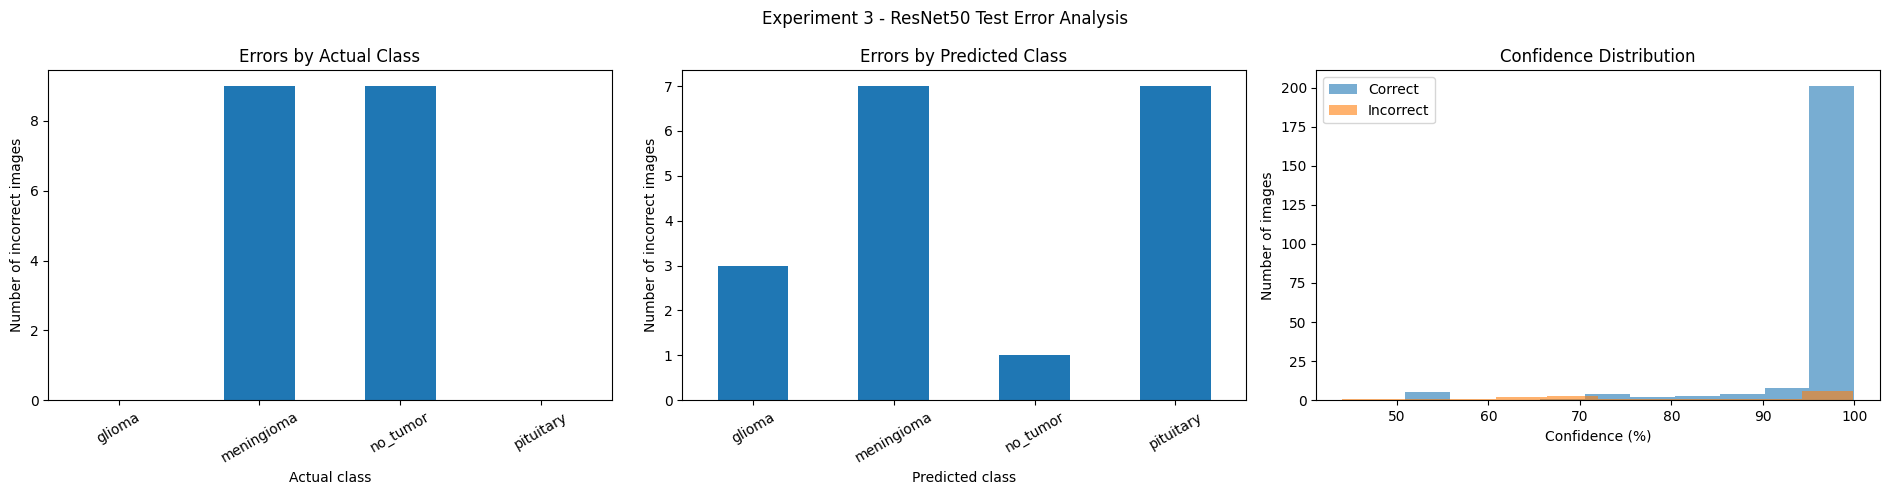


Displaying misclassified MRI images...


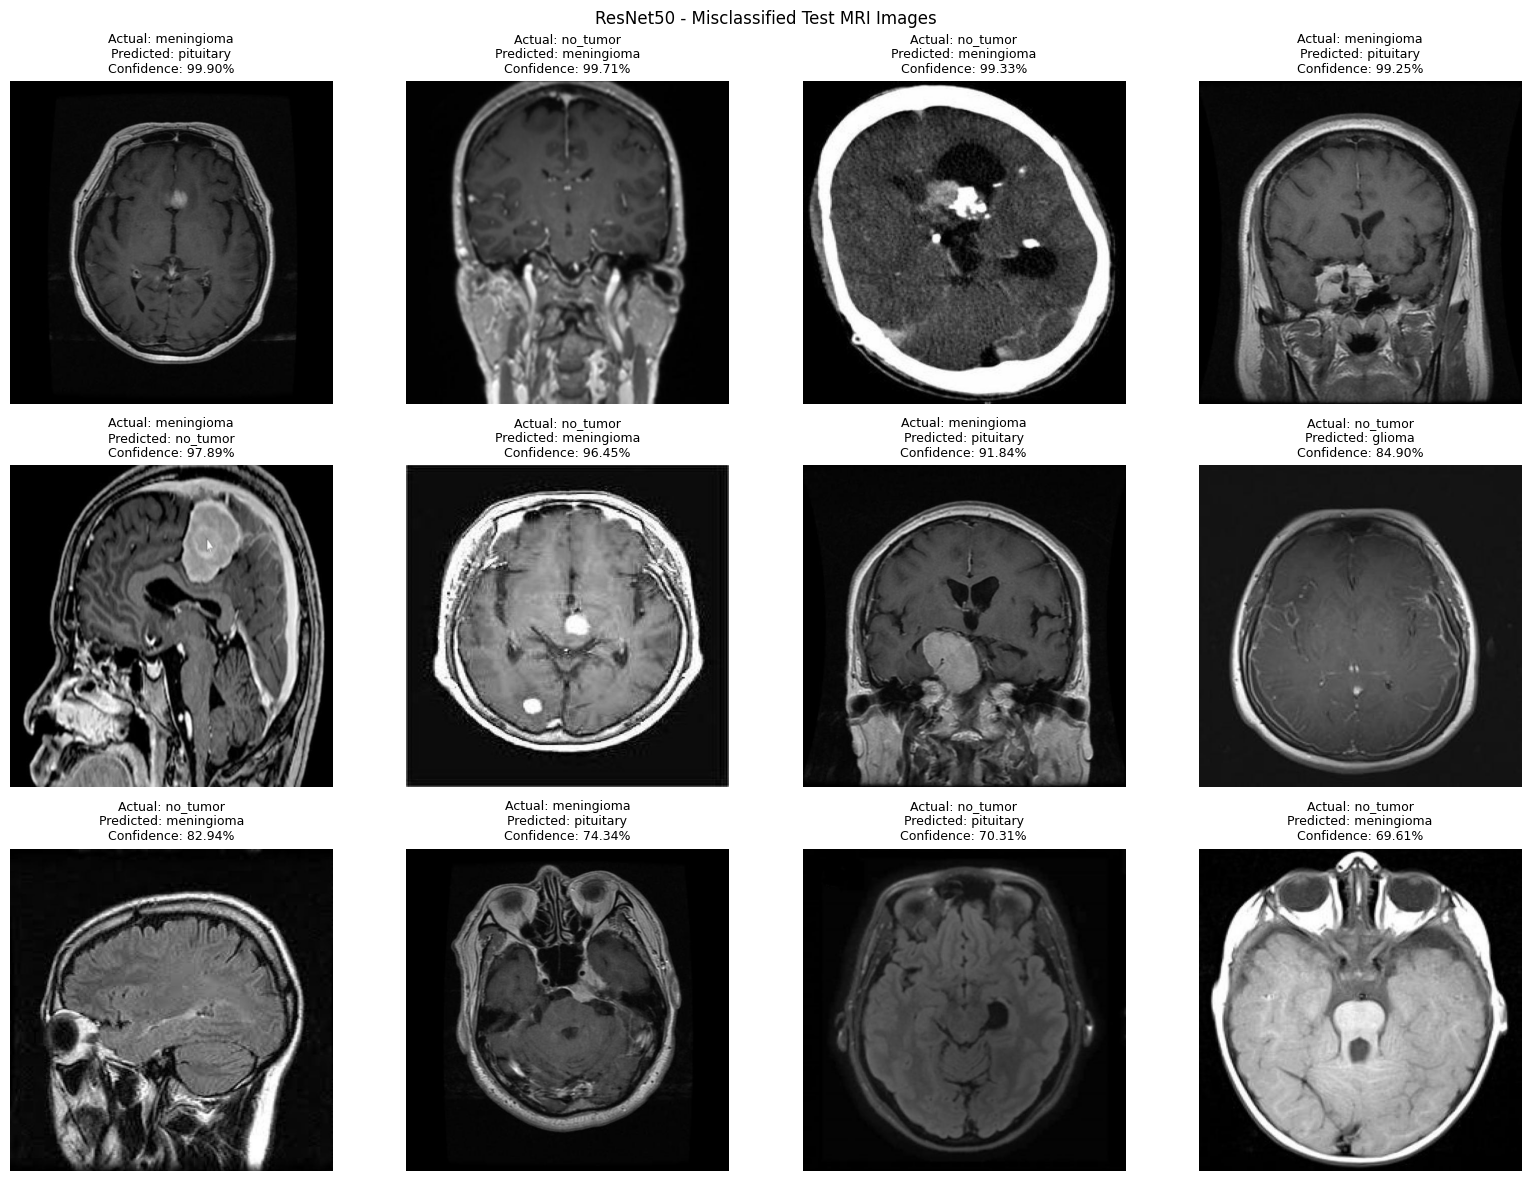


ERROR ANALYSIS COMPLETED
Total images analysed: 246
Correct: 228
Incorrect: 18
High-confidence errors: 9
Saved report: C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\resnet50_test_error_analysis.csv


In [ ]:

# ============================================================
# SECTION 9: COMPLETE RESNET50 TEST ERROR ANALYSIS
# One consolidated experiment - no retraining
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. DEFINE FILE LOCATIONS
# ------------------------------------------------------------

DATASET_DIR = Path(
    r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\Tumour"
)

REPORT_DIR = Path(
    r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50"
)

PREDICTION_FILE = REPORT_DIR / "resnet50_test_predictions.csv"

if not PREDICTION_FILE.exists():
    raise FileNotFoundError(
        f"Prediction report not found: {PREDICTION_FILE}"
    )

# ------------------------------------------------------------
# 2. LOAD SAVED TEST PREDICTIONS
# ------------------------------------------------------------

df = pd.read_csv(PREDICTION_FILE)

required_columns = [
    "Image", "Actual", "Predicted", "Confidence", "Correct"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing report columns: {missing_columns}"
    )

df["Confidence"] = pd.to_numeric(
    df["Confidence"], errors="coerce"
)

df["Correct"] = (
    df["Correct"].astype(str).str.lower().map(
        {"true": True, "false": False}
    )
)

if df["Correct"].isna().any():
    raise ValueError("Could not interpret the Correct column.")

# ------------------------------------------------------------
# 3. OVERALL ERROR SUMMARY
# ------------------------------------------------------------

total_images = len(df)

correct_count = int(df["Correct"].sum())

incorrect_count = total_images - correct_count

accuracy = correct_count / total_images * 100

print("=" * 65)
print("RESNET50 - TEST ERROR ANALYSIS")
print("=" * 65)

print("Total test images:", total_images)
print("Correct predictions:", correct_count)
print("Incorrect predictions:", incorrect_count)
print(f"Test accuracy: {accuracy:.2f}%")

# ------------------------------------------------------------
# 4. CONFIDENCE THRESHOLD ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CONFIDENCE THRESHOLD ANALYSIS")
print("=" * 65)

for threshold in [50, 60, 70, 80, 90]:

    accepted = df["Confidence"] >= threshold

    accepted_df = df[accepted]

    accepted_count = len(accepted_df)

    coverage = accepted_count / total_images * 100

    if accepted_count > 0:

        accepted_accuracy = (
            accepted_df["Correct"].mean() * 100
        )

        incorrect_accepted = int(
            (~accepted_df["Correct"]).sum()
        )

        print(
            f"\nThreshold: {threshold}%"
            f"\nAccepted: {accepted_count}/{total_images}"
            f"\nCoverage: {coverage:.2f}%"
            f"\nAccuracy among accepted: {accepted_accuracy:.2f}%"
            f"\nIncorrect accepted: {incorrect_accepted}"
        )

    else:
        print(f"\nThreshold {threshold}%: No accepted images")

# ------------------------------------------------------------
# 5. IDENTIFY INCORRECT PREDICTIONS
# ------------------------------------------------------------

errors = df[~df["Correct"]].copy()

errors = errors.sort_values(
    by="Confidence",
    ascending=False
)

print("\n" + "=" * 65)
print("MISCLASSIFICATION SUMMARY")
print("=" * 65)

error_summary = (
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Image_Count")
    .sort_values("Image_Count", ascending=False)
)

if len(error_summary) > 0:
    print(error_summary.to_string(index=False))
else:
    print("No incorrect predictions found.")

# ------------------------------------------------------------
# 6. CLASS-WISE ERROR COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ERRORS BY ACTUAL CLASS")
print("=" * 65)

print(
    errors.groupby("Actual").size()
    .reindex(sorted(df["Actual"].unique()), fill_value=0)
)

print("\n" + "=" * 65)
print("ERRORS BY PREDICTED CLASS")
print("=" * 65)

print(
    errors.groupby("Predicted").size()
    .reindex(sorted(df["Predicted"].unique()), fill_value=0)
)

# ------------------------------------------------------------
# 7. HIGH-CONFIDENCE INCORRECT PREDICTIONS
# ------------------------------------------------------------

high_confidence_errors = errors[
    errors["Confidence"] >= 80
]

print("\n" + "=" * 65)
print("HIGH-CONFIDENCE INCORRECT PREDICTIONS")
print("=" * 65)

print(
    "Incorrect predictions with confidence >= 80%:",
    len(high_confidence_errors)
)

if len(high_confidence_errors) > 0:
    print(
        high_confidence_errors[
            ["Image", "Actual", "Predicted", "Confidence"]
        ].to_string(index=False)
    )
else:
    print("No high-confidence incorrect predictions.")

# ------------------------------------------------------------
# 8. DISPLAY ERROR SUMMARY CHARTS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Errors by actual class
actual_counts = (
    errors["Actual"].value_counts()
    .reindex(sorted(df["Actual"].unique()), fill_value=0)
)

actual_counts.plot(
    kind="bar",
    ax=axes[0],
    title="Errors by Actual Class"
)

axes[0].set_ylabel("Number of incorrect images")
axes[0].set_xlabel("Actual class")
axes[0].tick_params(axis="x", rotation=30)

# Errors by predicted class
predicted_counts = (
    errors["Predicted"].value_counts()
    .reindex(sorted(df["Predicted"].unique()), fill_value=0)
)

predicted_counts.plot(
    kind="bar",
    ax=axes[1],
    title="Errors by Predicted Class"
)

axes[1].set_ylabel("Number of incorrect images")
axes[1].set_xlabel("Predicted class")
axes[1].tick_params(axis="x", rotation=30)

# Confidence distribution
axes[2].hist(
    df.loc[df["Correct"], "Confidence"],
    bins=10,
    alpha=0.6,
    label="Correct"
)

axes[2].hist(
    errors["Confidence"],
    bins=10,
    alpha=0.6,
    label="Incorrect"
)

axes[2].set_title("Confidence Distribution")
axes[2].set_xlabel("Confidence (%)")
axes[2].set_ylabel("Number of images")
axes[2].legend()

plt.suptitle("Experiment 3 - ResNet50 Test Error Analysis")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUALISE MISCLASSIFIED MRI IMAGES
# ------------------------------------------------------------

print("\nDisplaying misclassified MRI images...")

if len(errors) > 0:

    display_errors = errors.head(12)

    number_of_images = len(display_errors)

    columns = 4

    rows = int(np.ceil(number_of_images / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, rows * 4)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes, display_errors.iterrows()
    ):

        image_path = DATASET_DIR / "test" / str(row["Image"])

        if image_path.exists():

            image = Image.open(image_path).convert("RGB")

            ax.imshow(image)

            ax.set_title(
                f"Actual: {row['Actual']}\n"
                f"Predicted: {row['Predicted']}\n"
                f"Confidence: {row['Confidence']:.2f}%",
                fontsize=9
            )

            ax.axis("off")

        else:
            ax.set_title(
                f"Image not found:\n{row['Image']}",
                fontsize=8
            )

    plt.suptitle(
        "ResNet50 - Misclassified Test MRI Images"
    )

    plt.tight_layout()
    plt.show()

else:
    print("No misclassified images to display.")

# ------------------------------------------------------------
# 10. SAVE DETAILED ERROR REPORT
# ------------------------------------------------------------

ERROR_REPORT = REPORT_DIR / "resnet50_test_error_analysis.csv"

errors.to_csv(
    ERROR_REPORT,
    index=False
)

print("\n" + "=" * 65)
print("ERROR ANALYSIS COMPLETED")
print("=" * 65)

print("Total images analysed:", total_images)
print("Correct:", correct_count)
print("Incorrect:", incorrect_count)
print("High-confidence errors:", len(high_confidence_errors))
print("Saved report:", ERROR_REPORT)



## 9.5 Interpretation of ResNet50 Error Analysis

The ResNet50 model achieved 92.68% test accuracy.

Out of 246 test images:

- Correct predictions: 228
- Incorrect predictions: 18
- High-confidence incorrect predictions: 9

Most errors occurred in the meningioma and no_tumor categories.

The model sometimes produced incorrect predictions
with confidence above 90%.

This demonstrates that softmax confidence is not
a guarantee of prediction correctness.

Possible contributing factors include image variation,
overlapping visual features, dataset quality and
model limitations.

Further investigation is required before deploying
the model in any real-world medical setting.

No test images were used for retraining or tuning.



# SECTION 10: CUSTOM CNN VS RESNET50 COMPARISON

## 10.1 Purpose

We developed two models for brain tumor MRI classification.

Experiment 2: Custom CNN
Experiment 3: ResNet50 Transfer Learning

Both models were evaluated using the same test dataset
containing 246 images.

## 10.2 Comparison metrics

We compare:

1. Accuracy
2. Macro F1-score
3. Meningioma recall
4. No-tumor recall
5. Incorrect predictions

## 10.3 Comparison results

Custom CNN:
- Accuracy: 84.96%
- Macro F1: 83.89%
- Meningioma recall: 60.32%
- No-tumor recall: 89.80%
- Incorrect predictions: 37

ResNet50:
- Accuracy: 92.68%
- Macro F1: 92.01%
- Meningioma recall: 85.71%
- No-tumor recall: 81.63%
- Incorrect predictions: 18

## 10.4 Interpretation

ResNet50 achieved higher overall accuracy and
macro F1-score.

It substantially improved meningioma recall.

However, no-tumor recall decreased compared with
the Custom CNN.

Therefore, both overall performance and individual
class performance must be considered.


**What this block does:** This block places the Custom CNN and ResNet50 test metrics into one comparison table and visualizes their performance.

**Why it matters:** Use the comparison to discuss both overall results and class-specific trade-offs, rather than relying on accuracy alone.

FINAL MODEL COMPARISON
               Metric  Custom CNN  ResNet50
             Accuracy       84.96     92.68
             Macro F1       83.89     92.01
    Meningioma Recall       60.32     85.71
Incorrect Predictions       37.00     18.00


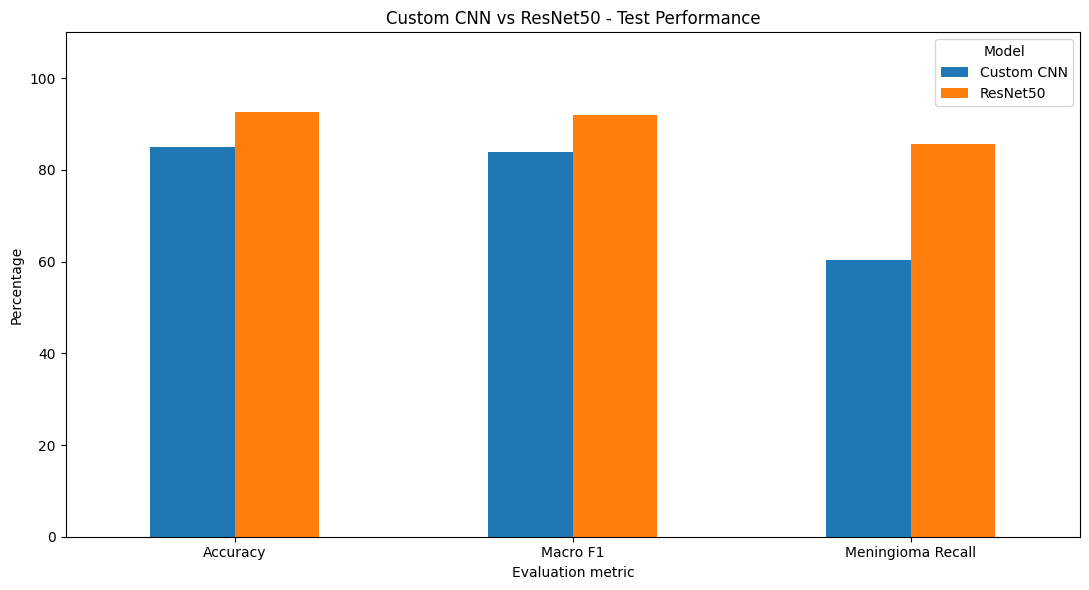


Incorrect prediction comparison:
               Metric  Custom CNN  ResNet50
Incorrect Predictions        37.0      18.0


In [ ]:

# ==================================================
# SECTION 10: CUSTOM CNN VS RESNET50
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Results from the completed experiments
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro F1",
        "Meningioma Recall",
        "Incorrect Predictions"
    ],
    "Custom CNN": [
        84.96,
        83.89,
        60.32,
        37
    ],
    "ResNet50": [
        92.68,
        92.01,
        85.71,
        18
    ]
})

print("FINAL MODEL COMPARISON")
print(comparison.to_string(index=False))

# Plot percentage metrics
percentage_metrics = comparison[
    comparison["Metric"] != "Incorrect Predictions"
]

ax = percentage_metrics.set_index("Metric").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Custom CNN vs ResNet50 - Test Performance")
plt.ylabel("Percentage")
plt.xlabel("Evaluation metric")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

# Compare incorrect predictions separately
error_comparison = comparison[
    comparison["Metric"] == "Incorrect Predictions"
]

print("\nIncorrect prediction comparison:")
print(error_comparison.to_string(index=False))



# SECTION 11: FINAL MODEL SELECTION

## 11.1 Objective

The objective is to select the best-performing model
from our two completed experiments.

## 11.2 Models evaluated

Experiment 2: Custom CNN

Experiment 3: ResNet50 Transfer Learning

Both models were evaluated using the same
246-image test dataset.

## 11.3 Final comparison

Custom CNN:
- Test Accuracy: 84.96%
- Macro F1: 83.89%
- Meningioma Recall: 60.32%
- No-tumor Recall: 89.80%
- Incorrect Predictions: 37

ResNet50:
- Test Accuracy: 92.68%
- Macro F1: 92.01%
- Meningioma Recall: 85.71%
- No-tumor Recall: 81.63%
- Incorrect Predictions: 18

## 11.4 Selected model

ResNet50 is selected as the leading model because
it achieved higher overall test accuracy,
higher macro F1-score and improved meningioma recall.

However, its no-tumor recall is lower than that
of the Custom CNN.

It also produced nine incorrect predictions with
confidence of at least 80%.

These limitations must be considered in the
application and final project documentation.

## 11.5 Final model location

experiment3_resnet50/models/best_resnet50_exp3.keras

## 11.6 Important limitation

ResNet50 is selected for this educational project
based on the available test results.

It is not a clinically validated diagnostic system.
Its predictions must not replace professional
medical assessment.


**What this block does:** This block records the final model-selection decision and the metrics supporting it.

**Why it matters:** It saves the selection summary as a CSV file so the chosen model and its limitations are documented.

In [ ]:

# ==================================================
# SECTION 11: FINAL MODEL SELECTION RECORD
# ==================================================

import pandas as pd
from pathlib import Path

final_selection = {
    "Selected Model": "ResNet50",
    "Test Accuracy": "92.68%",
    "Macro F1": "92.01%",
    "Meningioma Recall": "85.71%",
    "No Tumor Recall": "81.63%",
    "Incorrect Predictions": 18,
    "Confidence Threshold": "80% initial review threshold",
    "Model File": (
        "models/best_resnet50_exp3.keras"
    ),
    "Selection Reason": (
        "Higher overall accuracy and macro F1 "
        "than Custom CNN"
    )
}

selection_df = pd.DataFrame(
    list(final_selection.items()),
    columns=["Parameter", "Result"]
)

print("FINAL MODEL SELECTION")
print(selection_df.to_string(index=False))

# Save selection record
OUTPUT_DIR = Path(
    r"C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50"
)

selection_path = OUTPUT_DIR / "final_model_selection.csv"

selection_df.to_csv(
    selection_path,
    index=False
)

print("\nSelection record saved:")
print(selection_path)

print("\nSelected model: ResNet50")


FINAL MODEL SELECTION
            Parameter                                               Result
       Selected Model                                             ResNet50
        Test Accuracy                                               92.68%
             Macro F1                                               92.01%
    Meningioma Recall                                               85.71%
      No Tumor Recall                                               81.63%
Incorrect Predictions                                                   18
 Confidence Threshold                         80% initial review threshold
           Model File                      models/best_resnet50_exp3.keras
     Selection Reason Higher overall accuracy and macro F1 than Custom CNN

Selection record saved:
C:\Users\Gokul\Downloads\Brain_Tumor_Project_\experiment3_resnet50\final_model_selection.csv

Selected model: ResNet50
